# Proyecto final

## La forma del microbioma: de la geometría a la biología

En este proyecto van a trabajar con un conjunto de datos de microbioma humano acompañado de variables clínicas y dietarias. El objetivo es emplear herramientas geométricas y topológicas para responder preguntas concretas sobre estos datos.

## Preguntas centrales

**¿El microbioma se organiza como grupos separados o como un continuo?**

**¿Qué cambia de manera más clara al recorrer esa estructura: el perfil cardiometabólico o la dieta?**

---

## Cómo está diseñado este cuaderno

En este proyecto **no** se espera que exploren muchas variantes técnicas. Para que el foco esté en la interpretación, este cuaderno fija una representación razonable del microbioma y una construcción concreta de Mapper.

Su trabajo consiste en:

1. entender la forma global de los datos,
2. relacionar esa forma con variables clínicas y dietarias,
3. interpretar regiones y extremos de la estructura,
4. explorar al menos un camino alterno razonable,
5. y construir una conclusión biológica bien justificada.

---

## Entregable

Entreguen un cuaderno totalmente ejecutado que contenga:

- sus respuestas en las celdas de Markdown,
- todas las figuras y tablas generadas,
- una conclusión final clara y honesta,
- y al menos un intento de exploración alterna, aunque no haya producido una señal fuerte.

No se evalúa quién produce la gráfica más llamativa. Se evalúa qué tan bien conectan la geometría con la biología de los datos.

## Parte 0. Antes de empezar

En este proyecto vamos a trabajar con estas decisiones ya fijadas:

- **unidad de análisis:** cada muestra/persona será un punto,
- **nivel taxonómico principal:** género,
- **geometría principal:** Bray--Curtis sobre abundancias relativas,
- **control geométrico:** CLR a nivel de género,
- **Mapper principal:** lente = PCoA1 + densidad local.

La idea es que ustedes no peleen con hiperparámetros, sino que interpreten una estructura ya razonablemente construida.

In [ ]:
# Si trabajas en Colab, esta celda instala la librería que falta.
# Si ya está instalada, no pasa nada.

try:
    import kmapper as km
except ModuleNotFoundError:
    !pip -q install kmapper
    import kmapper as km

In [ ]:
from pathlib import Path
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
import kmapper as km
import matplotlib.patches as mpatches
import umap

from umap import UMAP
from scipy.stats import mannwhitneyu
from sklearn.cluster import DBSCAN
from sklearn.decomposition import PCA
from sklearn.metrics import pairwise_distances, silhouette_score
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler

plt.rcParams["figure.figsize"] = (7, 4)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

In [ ]:
# Si trabajas en Colab, esta celda instala las librerías topológicas que faltan.
# Si ya están instaladas, no pasa nada.

try:
    from ripser import ripser
    from persim import plot_diagrams
except ModuleNotFoundError:
    !pip -q install ripser persim
    from ripser import ripser
    from persim import plot_diagrams

In [ ]:
BASE = Path(".").resolve()

def find_data_folder():
    if (BASE / "microbio_selected.meta").exists():
        return BASE
    if (BASE / "datos.zip").exists():
        out = BASE / "datos_extraidos"
        out.mkdir(exist_ok=True)
        with zipfile.ZipFile(BASE / "datos.zip", "r") as z:
            z.extractall(out)
        return out
    raise FileNotFoundError("No encontré los archivos. Pon aquí el zip datos.zip o los archivos descomprimidos.")

DATA = find_data_folder()

meta = pd.read_csv(DATA / "microbio_selected.meta", sep="\t")
otus = pd.read_csv(DATA / "microbio_selected.otus", sep="\t")
taxonomy = pd.read_csv(DATA / "microbio_selected.taxonomy", sep="\t")

print("meta:", meta.shape)
print("otus:", otus.shape)
print("taxonomy:", taxonomy.shape)

meta: (446, 32)
otus: (446, 4739)
taxonomy: (4738, 3)


<br>

## Parte 1. Entender la forma de los datos

Antes de construir la representación geométrica, revisen qué tipo de tablas están usando.

### Pregunta 1
Expliquen brevemente:

- qué representa una fila en `meta`,
- qué representa una fila en `otus`,
- y por qué tiene sentido pensar que cada muestra será un punto.

In [ ]:
meta.head()

,ID,city,sex,age,age_range,HDL,LDL,cholesterol,triglycerides,hsCRP,...,waist,medicament,fiber,per_protein,per_animal_protein,per_total_fat,per_saturated_fat,per_monoinsaturated_fat,per_polyunsaturated_fat,per_carbohydrates
0,MI_001_H,Medellin,Male,36,18_40,38,93,170,195,"1,71",...,"97,6",No,19,"16,15","60,53","28,4","11,01","9,88","4,82","55,47"
1,MI_002_H,Medellin,Female,40,18_40,52,130,202,100,"0,32",...,"89,3",No,13,"13,77","66,88","29,74","11,61","10,35","6,55","56,1"
2,MI_003_H,Medellin,Male,53,41_62,51,119,185,76,"1,84",...,"92,8",No,13,"14,57","64,75","24,2","9,48","8,1","4,84","61,37"
3,MI_004_H,Medellin,Male,58,41_62,59,120,199,99,"0,86",...,"84,7",Yes,16,"19,17","65,78","28,72","11,6","10,63","5,03","51,28"
4,MI_005_H,Medellin,Female,44,41_62,73,63,159,114,"0,43",...,"73,3",Yes,21,"13,86","59,4","28,4","9,91","9,66","6,92","57,5"


In [ ]:
otus.iloc[:5, :8]

,samples,Otu00001,Otu00002,Otu00003,Otu00004,Otu00005,Otu00006,Otu00007
0,MI_001_H,354,817,50,31,448,547,727
1,MI_002_H,168,9,131,3005,68,10187,570
2,MI_003_H,19,174,6211,79,1063,0,6077
3,MI_004_H,264,1816,159,16,110,4,12
4,MI_005_H,0,2,0,12,598,39,0


In [ ]:
taxonomy.head()

,OTU,Size,Taxonomy
0,Otu00001,136589,k__Bacteria;p__Bacteroidetes;c__Bacteroidia;o_...
1,Otu00002,1139018,k__Bacteria;p__Bacteroidetes;c__Bacteroidia;o_...
2,Otu00003,452087,k__Bacteria;p__Firmicutes;c__Clostridia;o__Clo...
3,Otu00004,1182065,k__Bacteria;p__Proteobacteria;c__Gammaproteoba...
4,Otu00005,265091,k__Bacteria;p__Firmicutes;c__Clostridia;o__Clo...


### Respuesta del equipo

* El archivo `meta` contiene el historial clínico de los sujetos del estudio, en donde cada fila contiene los datos médicos del paciente correspondiente.

* En el caso de `otus`, este archivo contiene la información detallada referente a la microbiota de cada uno; se refiere a la presencia de microbiomas en el paciente.

* Dado que ambas tablas buscan explorar la relación entre la composición microbiana y la salud de las personas, es natural representar cada muestra como un punto en el espacio de datos. Al combinar la información de ambas fuentes, cada punto corresponde a un paciente e incorpora el perfil completo de microorganismos presentes en su organismo. De esta forma, la proximidad o distancia entre puntos refleja qué tan similares o distintos son los microbiomas de diferentes individuos, lo que permite identificar patrones de agrupamiento relacionados con distintos estados de salud.

### Limpieza mínima y agregación a género

Vamos a transformar los datos de OTUs a nivel de género. Esto reduce ruido y hace más interpretable la composición microbiana.

In [ ]:
meta_clean = meta.copy()

for col in meta_clean.columns:
    if meta_clean[col].dtype == object:
        s = meta_clean[col].astype(str).str.replace(",", ".", regex=False)
        conv = pd.to_numeric(s, errors="coerce")
        nonnull = meta_clean[col].notna().sum()
        if (
            nonnull > 0
            and conv.notna().sum() / nonnull > 0.8
            and col not in [
                "ID", "city", "sex", "age_range",
                "stool_consistency", "hiden_blood",
                "bmi_class", "medicament"
            ]
        ):
            meta_clean[col] = conv

meta_clean = meta_clean.set_index("ID")
otus_counts = otus.set_index("samples").loc[meta_clean.index]

def extract_rank(tax_str, prefix):
    if pd.isna(tax_str):
        return "Unassigned"
    for part in str(tax_str).split(";"):
        if part.startswith(prefix):
            value = part[len(prefix):].strip()
            return value if value else "Unassigned"
    return "Unassigned"

taxonomy["genus"] = taxonomy["Taxonomy"].apply(lambda s: extract_rank(s, "g__"))
otu_to_genus = taxonomy.set_index("OTU")["genus"]

common = [c for c in otus_counts.columns if c in otu_to_genus.index]
genus_counts = otus_counts[common].T.groupby(otu_to_genus.loc[common]).sum().T

print("Matriz a nivel de género:", genus_counts.shape)
print("Valores faltantes en metadata:", int(meta_clean.isna().sum().sum()))

Matriz a nivel de género: (446, 430)
Valores faltantes en metadata: 3


Esta salida significa que en toda la tabla de metadata, solamente hay tres celdas vacías.


In [ ]:
X_rel = genus_counts.div(genus_counts.sum(axis=1), axis=0)

sparsity = 1 - (X_rel.to_numpy() > 0).mean()
print(f"Fracción de ceros en la matriz a nivel de género: {sparsity:.3f}")

present_in = (X_rel > 0).mean(axis=0)
present_in.describe()

Fracción de ceros en la matriz a nivel de género: 0.814


,0
count,430.000000
mean,0.186036
std,0.307470
min,0.002242
25%,0.002242
50%,0.013453
75%,0.211883
max,1.000000


In [ ]:
present_in.head()

,0
genus,
02d06,0.860987
1-68,0.226457
AF12,0.076233
Abiotrophia,0.091928
Acanthamoeba,0.002242


Solo el 16% de las celdas tienen algún valor, lo que confirma que cada persona carga únicamente un subconjunto pequeño de todos los géneros detectados en el estudio.

### Pregunta 2
Comenten dos cosas:

1. ¿Qué se gana al pasar de OTU a género?
2. ¿Qué se pierde?

### Respuesta del equipo
Se gana:
- Interpretabilidad: los géneros tienen nombre y significado biológico conocido, mientras que un OTU es simplemente una secuencia de ADN sin contexto claro.
- Claridad: Al haber distintas profundidades de secuenciación (dependiendo el equipo con el que se toma la muestra), habrá OTUs que solamente aparezcan en ciertas muestras y en otras no, pero esto no necesariamente significa un hallazgo real. Usar el género al agrupar OTUs reduce el ruido estadístico.

Y se pierde:
- Resolución taxonómica: Si bien, el género es una categoría bastante específica todavía, un mismo género puede tener especies completamente distintas, con funciones opuestas entre si y diferentes características. Este agrupamiento hará imposible notar diferencias sútiles entre las muestras.


Se sacrifica especificidad a cambio de robustez.

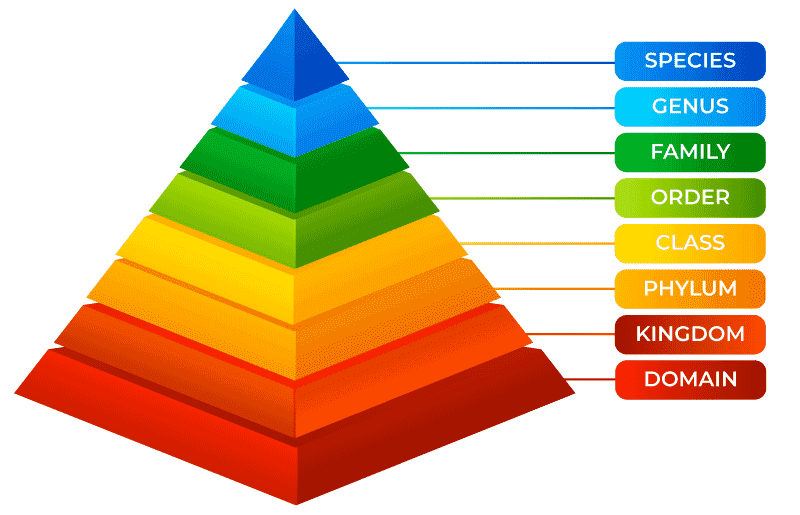

## Parte 2. Construir la geometría principal

Usaremos Bray--Curtis sobre abundancias relativas a nivel de género y luego una representación PCoA.

In [ ]:
D_bray = pairwise_distances(X_rel.values, metric="braycurtis")

def pcoa(D, n_components=10):
    n = D.shape[0]
    H = np.eye(n) - np.ones((n, n)) / n
    B = -0.5 * H @ (D ** 2) @ H
    eigvals, eigvecs = np.linalg.eigh(B)
    idx = np.argsort(eigvals)[::-1]
    eigvals = eigvals[idx]
    eigvecs = eigvecs[:, idx]
    pos = eigvals > 1e-10
    eigvals = eigvals[pos]
    eigvecs = eigvecs[:, pos]
    k = min(n_components, eigvecs.shape[1])
    return eigvecs[:, :k] * np.sqrt(eigvals[:k]), eigvals[:k]

coords_bray, eig_bray = pcoa(D_bray, 10)
print("Varianza relativa explicada por PCoA 1--5:", np.round(eig_bray / eig_bray.sum(), 3)[:5])

Varianza relativa explicada por PCoA 1--5: [0.217 0.176 0.164 0.108 0.078]


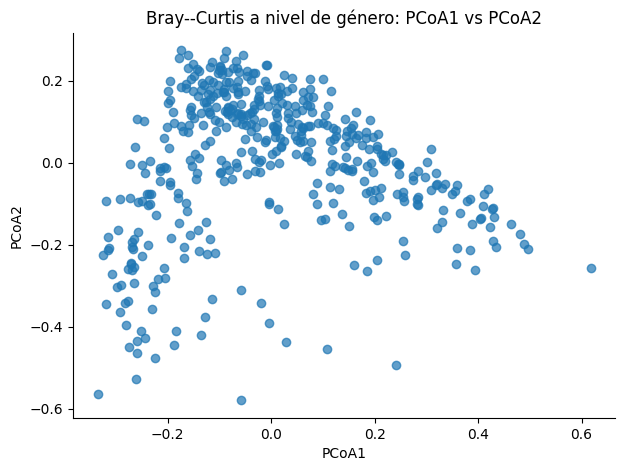

In [ ]:
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(coords_bray[:, 0], coords_bray[:, 1], alpha=0.7)
ax.set_title("Bray--Curtis a nivel de género: PCoA1 vs PCoA2")
ax.set_xlabel("PCoA1")
ax.set_ylabel("PCoA2")
plt.show()

In [ ]:
from scipy.stats import gmean

def clr(X):
    # Añadir pseudocuenta para evitar log(0)
    X = X + 1e-6
    gm = gmean(X, axis=1, keepdims=True)
    return np.log(X / gm)

X_clr = clr(X_rel.values)
D_clr = pairwise_distances(X_clr, metric="euclidean")

def pcoa(D, n_components=10):
    n = D.shape[0]
    H = np.eye(n) - np.ones((n, n)) / n
    B = -0.5 * H @ (D ** 2) @ H
    eigvals, eigvecs = np.linalg.eigh(B)
    idx = np.argsort(eigvals)[::-1]
    eigvals = eigvals[idx]
    eigvecs = eigvecs[:, idx]
    pos = eigvals > 1e-10
    eigvals = eigvals[pos]
    eigvecs = eigvecs[:, pos]
    k = min(n_components, eigvecs.shape[1])
    return eigvecs[:, :k] * np.sqrt(eigvals[:k]), eigvals[:k]

coords_clr, eig_clr = pcoa(D_clr, 10)
print("Varianza relativa explicada por PCoA 1--5:", np.round(eig_clr / eig_clr.sum(), 3)[:5])

Varianza relativa explicada por PCoA 1--5: [0.258 0.172 0.124 0.087 0.075]


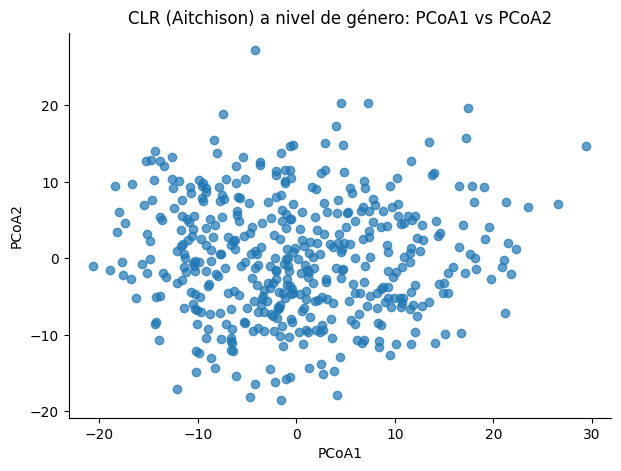

In [ ]:
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(coords_clr[:, 0], coords_clr[:, 1], alpha=0.7)
ax.set_title("CLR (Aitchison) a nivel de género: PCoA1 vs PCoA2")
ax.set_xlabel("PCoA1")
ax.set_ylabel("PCoA2")
plt.show()

### Pregunta 3
A partir de esta proyección, den una primera impresión:

- ¿ven grupos claramente separados?
- ¿ven una nube continua?
- ¿ven indicios de regiones o ramas?

No den una respuesta definitiva todavía. Solo una impresión inicial.

### Respuesta del equipo
Es importante tomar en cuenta en esta respuesta, que solamente se está explicando el 39% aproximadamente de la varianza, que es muy poco para dar una respuesta definitiva aún. En el caso de Bray curtis, se ven dos ramas que se surgen de un mismo punto del gráfico. Si bien no son ramas completamente separadas y hay que seguir explorando si hay más opciones, es un buen indicio de que sí podría existir continuidad.

En el caso de CLR, se encuentra una nube con los puntos cercanos unos a otros. No se pueden observar ramas o bifurcaciones, por lo que no se podría asegurar una continuidad.

Sabiendo esto, se podrían utilizar otras técnicas de reducción de dimensionalidad. Para una ruta alterna se utilizaría UMAP, el cual es un algoritmo para la reducción de dimensionalidad vecindad entre los puntos, no por distancias en sí.


## Parte 2A. Vecindad, abiertos y cerrados

La métrica fija qué muestras quedan cerca. Con esa noción de cercanía se definen vecindades, bolas abiertas y bolas cerradas.

### Pregunta topológica 1

Respondan brevemente:

- qué sería aquí una **bola abierta** de radio \(r\) alrededor de una muestra,
- qué sería aquí una **bola cerrada** de radio \(r\),
- por qué cambiar de Bray--Curtis a CLR cambia la noción de cercanía y, por tanto, la topología del conjunto de datos.

### Respuesta del equipo

Una bola se forma alrededor de cada muestra, uniendo a las personas que estén dentro del rango establecido \(r\). En una bola cerrada sí se incluyen a las personas que estén en el borde de la bola, a diferencia de una bola abierta, en dónde las personas justo en el borde no se incluyen. Ambos tipos de bola incluyen a las personas que estén a una distancia menor de \(r\).


Tomando en cuenta que:
- Bray-Curtis mide disimilitud basándose en las proporciones de géneros compartidos — dos personas son cercanas si tienen géneros similares en abundancias parecidas. Es sensible a los ceros: si un género está ausente en ambas, eso también cuenta.
- CLR primero transforma los datos con logaritmos y luego usa distancia euclidiana — esto cambia el peso que le da a géneros raros versus abundantes.


Como los vecinos de cada punto cambian según la métrica, las bolas cambian de forma y tamaño, y por tanto cambia qué puntos están conectados, qué grupos se forman y qué huecos o estructuras detecta la topología.

## Parte 2B. Homología persistente de la forma global

Usen una filtración de Vietoris--Rips en dimensión 0 y 1 para estudiar la forma global de los datos.

En este contexto:

- \( \beta_0 \) cuenta componentes conexas,
- \( \beta_1 \) cuenta ciclos.

Calcularemos homología persistente para dos geometrías:

- Bray--Curtis a nivel de género,
- CLR a nivel de género.

In [ ]:
# Construcción del control CLR para la comparación topológica

X_pc_top = genus_counts + 0.5
X_comp_top = X_pc_top.div(X_pc_top.sum(axis=1), axis=0)
logX_top = np.log(X_comp_top.values)
X_clr_top = logX_top - logX_top.mean(axis=1, keepdims=True)
X_clr_top = StandardScaler().fit_transform(X_clr_top)

D_clr_top = pairwise_distances(X_clr_top, metric="euclidean")

def normalize_distance_matrix(D):
    D = np.asarray(D, dtype=float).copy()
    nz = D[D > 0]
    scale = np.median(nz)
    return D / scale

D_bray_top = normalize_distance_matrix(D_bray)
D_clr_top = normalize_distance_matrix(D_clr_top)

ph_bray = ripser(D_bray_top, distance_matrix=True, maxdim=1)["dgms"]
ph_clr = ripser(D_clr_top, distance_matrix=True, maxdim=1)["dgms"]

print("Bray y CLR listos para homología persistente.")

Bray y CLR listos para homología persistente.


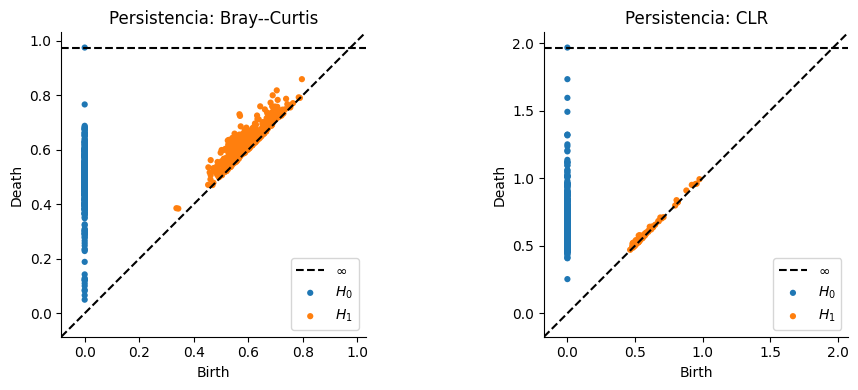

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

plot_diagrams(ph_bray, ax=axes[0], show=False)
axes[0].set_title("Persistencia: Bray--Curtis")

plot_diagrams(ph_clr, ax=axes[1], show=False)
axes[1].set_title("Persistencia: CLR")

plt.tight_layout()
plt.show()

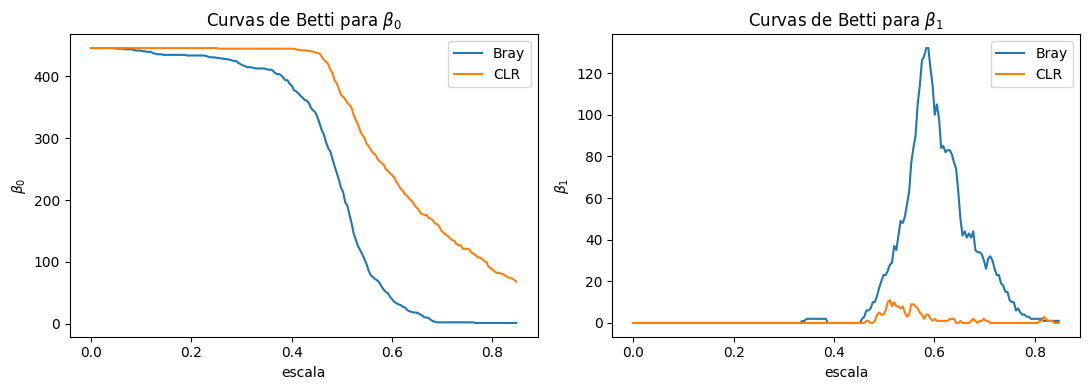

Resumen topológico


,geometry,max_persistence_beta0,median_persistence_beta0,max_persistence_beta1,median_persistence_beta1,n_beta1_bars,n_beta1_persistence_gt_0.20
0,Bray--Curtis,0.766177,0.497362,0.162526,0.026011,477,0
1,CLR,1.732616,0.613592,0.047766,0.007813,84,0


Top persistencias en H1 para Bray--Curtis


,birth,death,persistence
0,0.567729,0.730255,0.162526
1,0.569741,0.724101,0.154361
2,0.643830,0.759249,0.115420
3,0.572284,0.685810,0.113526
4,0.704547,0.817834,0.113287
5,0.689612,0.799770,0.110159
6,0.549719,0.659145,0.109426
7,0.524818,0.633801,0.108983
8,0.528518,0.636100,0.107583
9,0.541194,0.643067,0.101872


Top persistencias en H1 para CLR


,birth,death,persistence
0,0.527552,0.575318,0.047766
1,0.535047,0.578545,0.043498
2,0.484153,0.521026,0.036874
3,0.506448,0.541428,0.034981
4,0.481903,0.513213,0.031311
5,0.609346,0.640554,0.031208
6,0.488915,0.519490,0.030575
7,0.920598,0.950594,0.029996
8,0.498724,0.528669,0.029946
9,0.807777,0.837380,0.029602


In [ ]:
def betti_curve(diagram, grid):
    d = np.asarray(diagram, dtype=float)
    counts = []
    for t in grid:
        alive = (d[:, 0] <= t) & ((t < d[:, 1]) | np.isinf(d[:, 1]))
        counts.append(int(alive.sum()))
    return np.array(counts)

def persistence_table(diagram, top_n=10):
    d = np.asarray(diagram, dtype=float)
    finite = d[np.isfinite(d[:, 1])]
    if len(finite) == 0:
        return pd.DataFrame(columns=["birth", "death", "persistence"])
    pers = finite[:, 1] - finite[:, 0]
    order = np.argsort(-pers)
    out = pd.DataFrame(finite[order], columns=["birth", "death"])
    out["persistence"] = pers[order]
    return out.head(top_n)

def persistence_summary(diagrams, geometry):
    h0 = np.asarray(diagrams[0], dtype=float)
    h1 = np.asarray(diagrams[1], dtype=float)

    h0f = h0[np.isfinite(h0[:, 1])]
    h1f = h1[np.isfinite(h1[:, 1])]

    p0 = h0f[:, 1] - h0f[:, 0] if len(h0f) else np.array([])
    p1 = h1f[:, 1] - h1f[:, 0] if len(h1f) else np.array([])

    return {
        "geometry": geometry,
        "max_persistence_beta0": p0.max() if len(p0) else np.nan,
        "median_persistence_beta0": np.median(p0) if len(p0) else np.nan,
        "max_persistence_beta1": p1.max() if len(p1) else np.nan,
        "median_persistence_beta1": np.median(p1) if len(p1) else np.nan,
        "n_beta1_bars": len(p1),
        "n_beta1_persistence_gt_0.20": int((p1 > 0.20).sum()) if len(p1) else 0,
    }

finite_h0_deaths = []
finite_h1_deaths = []
for dgms in [ph_bray, ph_clr]:
    for dim in [0, 1]:
        d = np.asarray(dgms[dim], dtype=float)
        finite = d[np.isfinite(d[:, 1])]
        if len(finite):
            finite_h0_deaths.extend(finite[:, 1].tolist()) if dim == 0 else finite_h1_deaths.extend(finite[:, 1].tolist())

max_scale = np.percentile(finite_h0_deaths + finite_h1_deaths, 95)
grid = np.linspace(0, max_scale, 200)

b0_bray = betti_curve(ph_bray[0], grid)
b1_bray = betti_curve(ph_bray[1], grid)
b0_clr = betti_curve(ph_clr[0], grid)
b1_clr = betti_curve(ph_clr[1], grid)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].plot(grid, b0_bray, label="Bray")
axes[0].plot(grid, b0_clr, label="CLR")
axes[0].set_title(r"Curvas de Betti para $\beta_0$")
axes[0].set_xlabel("escala")
axes[0].set_ylabel(r"$\beta_0$")
axes[0].legend()

axes[1].plot(grid, b1_bray, label="Bray")
axes[1].plot(grid, b1_clr, label="CLR")
axes[1].set_title(r"Curvas de Betti para $\beta_1$")
axes[1].set_xlabel("escala")
axes[1].set_ylabel(r"$\beta_1$")
axes[1].legend()

plt.tight_layout()
plt.show()

summary_top = pd.DataFrame([
    persistence_summary(ph_bray, "Bray--Curtis"),
    persistence_summary(ph_clr, "CLR"),
])
print("Resumen topológico")
display(summary_top)

print("Top persistencias en H1 para Bray--Curtis")
display(persistence_table(ph_bray[1], 10))

print("Top persistencias en H1 para CLR")
display(persistence_table(ph_clr[1], 10))

### Pregunta topológica 2

A partir de los diagramas, las curvas de Betti y la tabla resumen, respondan:

- qué sugiere \( \beta_0 \) sobre la conectividad global de los datos,
- qué sugiere \( \beta_1 \) sobre la presencia de ciclos fuertes o débiles,
- qué geometría deja una lectura topológica más clara,
- y por qué esta parte topológica justifica el uso posterior de Mapper.

### Respuesta del equipo
Sobre la conectividad de los datos, la curva de Betti para \( $\beta_0$ \) sugiere que no hay grupos bien definidos. Se empiezan con los +400 puntos relativamente separados y empiezan a bajar con una pendiente controlada en ambas topologías. Si bien, con Bray esta bajada es mucho más pronunciada que con CLR; ambas tienen un comportamiento similar en ese sentido.
Esta bajada tan limpia significa que, conforme la distancia crece los grupos existentes se unen entre ellos a un ritmo constante. Si hubiera un punto en el que la bajada tuviera una especie de planicie antes de volver a bajar, sí se podría interpretar como que los grupos existentes en ese punto sí están separados; pero ese no es el caso en estos gráficos.



Por otro lado, las curvas de Betti para \( $\beta_1$ \) tienen comportamientos a simple vista muy distintos según la topología. Primero, Bray tiene un pico muy alto y muy exagerado que empieza al rededor de la escala 0.4, llega a su punto máximo con un valor de  \( $\beta_1$ \) alrededor de 120 en la escala 0.6 aproximadamente, pero inmediatamente empieza a bajar en picada, llegando al suelo en la escala 0.8. Este pico tan marcado, y el hecho de que desaparezca tan rápido indica que, si bien sí se forman varios ciclos, estos no son robustos y mueren muy rápido. Luego, CLR también tiene un pico, aunque mucho más pequeño y menos agresivo (más planito). Empieza al rededor de 0.5, llega al 10 y para el 0.6 ya ha desaparecido. Esto quiere decir que, si bien no se forman tantos ciclos, sí hay un punto en el que se forman pero desaparecen casi inmediatamente. El hecho de que estos picos desaparezcan tan rápido parecen indicar que no hay realmente ciclos y que se trata, más bien, de ruido topológico.



La geometría que deja una lectura topológica más clara sería la de CLR, pues no es tan susceptible al ruido en \( $\beta_1$ \) y en \($ \beta_0$ \) conserva a las componentes conexas un poco más de tiempo que Bray. Esto es una ventaja porque significa que, al no desaparecer tan rápido, los grupos son un poco más estables y están mejor definidos. Sin embargo, esto no es suficiente para concluir que haya grupos claramente definidos. Es por esta razón que el siguiente paso es explorar con Mapper; pues se sabe que no hay grupos ni ciclos robustos pero todavía es necesario identificar la forma de la estructura que forman los datos y relacionarla con variables clínicas que permitan generar una conclusión válida con hallazgos más robustos.


## Parte 3. Controles categóricos rápidos

Antes de usar Mapper, revisamos si categorías gruesas como `city`, `sex` o `bmi_class` organizan realmente la representación Bray.

In [ ]:
X_bray5 = StandardScaler().fit_transform(coords_bray[:, :5])

cat_vars = ["city", "sex", "age_range", "bmi_class", "stool_consistency", "medicament", "hiden_blood"]
cat_rows = []
for var in cat_vars:
    y = meta_clean[var].fillna(meta_clean[var].mode().iloc[0])
    sil = silhouette_score(X_bray5, y)
    cat_rows.append({"variable": var, "silhouette": sil, "niveles": y.nunique()})

cat_df = pd.DataFrame(cat_rows).sort_values("silhouette", ascending=False)
cat_df

,variable,silhouette,niveles
6,hiden_blood,0.072733,2
1,sex,0.011983,2
4,stool_consistency,0.008369,4
5,medicament,0.007968,2
2,age_range,0.002403,2
3,bmi_class,-0.013512,3
0,city,-0.039281,5


### Pregunta 4
Interpreten esta tabla.

- ¿Qué variables categóricas parecen organizar mejor la nube?
- ¿Hay alguna con separación realmente fuerte?
- ¿Qué les sugiere esto sobre la pregunta “clusters o continuo”?

### Respuesta del equipo
El silhouette funciona midiendo qué tanto una variable categórica separa a un conjunto de datos. Divide a los puntos acorde al nivel que tengan (mientras más grupos tenga que hacer menor se espera que sea el valor) y mide qué tanto, de -1 a 1, difieren las muestras de esas categorías.

Según los valores obtenidos para el silhouette, la mejor variable sería "hidden_blood" porque de todas, es la que tiene el valor más alto. Es muy peculiar que haya variables con silhouette negativa, pues eso significa que en esa división, están más cerca de otro grupo que de ese. Sin embargo, aún así, todos son valores muy cercanos al cero, indicando que realmente no existe una separación clara con ninguna de las variables categóricas analizadas en este punto.

## Parte 4. Construir dos perfiles continuos

Vamos a trabajar con dos tipos de variables continuas:

- un **perfil cardiometabólico**,
- y un **perfil dietario**.

El objetivo no es solo ver si cambian, sino si cambian de forma coherente con la estructura geométrica encontrada.

In [ ]:
# Perfil cardiometabólico
met_pos = ["waist", "glucose", "triglycerides", "HOMA_IR", "bmi", "diastolic_bp"]
met_neg = ["HDL", "adiponectin"]

M = meta_clean[met_pos + met_neg].copy().fillna(meta_clean[met_pos + met_neg].median())
M_std = (M - M.mean()) / M.std(ddof=0)
meta_clean["met_score"] = M_std[met_pos].mean(axis=1) - M_std[met_neg].mean(axis=1)

# Perfil dietario simple
diet_cols = ["fiber", "per_carbohydrates", "per_animal_protein", "per_total_fat", "per_saturated_fat"]
D = meta_clean[diet_cols].copy().fillna(meta_clean[diet_cols].median())
D_std = (D - D.mean()) / D.std(ddof=0)
meta_clean["diet_score_simple"] = (
    D_std["fiber"]
    + D_std["per_carbohydrates"]
    - D_std["per_animal_protein"]
    - D_std["per_total_fat"]
    - D_std["per_saturated_fat"]
)

# Perfil dietario por PCA
diet_vars = [
    "fiber", "per_protein", "per_animal_protein", "per_total_fat",
    "per_saturated_fat", "per_monoinsaturated_fat",
    "per_polyunsaturated_fat", "per_carbohydrates"
]
Diet = meta_clean[diet_vars].copy().fillna(meta_clean[diet_vars].median())
diet_pcs = PCA(n_components=3).fit_transform(StandardScaler().fit_transform(Diet))
meta_clean["diet_score_pca"] = -diet_pcs[:, 0]

meta_clean[["met_score", "diet_score_simple", "diet_score_pca"]].corr()

,met_score,diet_score_simple,diet_score_pca
met_score,1.000000,0.013695,0.001371
diet_score_simple,0.013695,1.000000,0.939879
diet_score_pca,0.001371,0.939879,1.000000


### Pregunta 5
Miren la correlación entre estos tres scores.

- ¿El perfil cardiometabólico y el dietario son casi lo mismo?
- ¿O parecen capturar cosas distintas?

### Respuesta del equipo
Comparar diet_score_simple y diet_score_pca no tiene sentido; el PCA simplemente encuentra automáticamente los pesos óptimos, pero la dirección principal que captura es esencialmente la misma que la combinación manual. Es de esperarse que estén altamente correlacionados. En el análisis posterior se estará usando únicamente diet_score_pca para comparar, pues basta con usar uno y se prefiere el enfoque automático del PCA.


Entre met_score y diet_score_pca hay una correlación de 0.001371, que es muy baja. Con esto se concluye que estos dos scores son independientes, aunque se esperaría ver que la dieta de las personas tuviera una correlación importante con el perfil cardiometabólico; se están comparando cosas bastante distintas.

## Parte 5. Mapper principal

Ahora construimos un Mapper fijo:

- geometría: Bray--Curtis a nivel de género,
- lente: PCoA1 + densidad local,
- clustering local: DBSCAN con parámetros fijos.

El objetivo no es optimizar Mapper, sino interpretar su estructura.

In [ ]:
def knn_density(X, k=15):
    nbrs = NearestNeighbors(n_neighbors=k).fit(X)
    dists, _ = nbrs.kneighbors(X)
    return dists[:, 1:].mean(axis=1)

density = knn_density(X_bray5, 15)
lens = np.c_[coords_bray[:, 0], density]
lens = (lens - lens.min(axis=0)) / (lens.max(axis=0) - lens.min(axis=0))

mapper = km.KeplerMapper(verbose=0)
graph = mapper.map(
    lens=lens,
    X=X_bray5,
    cover=km.Cover(n_cubes=10, perc_overlap=0.35),
    clusterer=DBSCAN(eps=1.0, min_samples=4),
)

def graph_to_nx(graph):
    G = nx.Graph()
    for node, members in graph["nodes"].items():
        G.add_node(node, members=members, size=len(members))
    for node, neighbors in graph["links"].items():
        for nb in neighbors:
            G.add_edge(node, nb)
    return G

G = graph_to_nx(graph)

covered = set()
for members in graph["nodes"].values():
    covered.update(members)

summary = {
    "nodes": G.number_of_nodes(),
    "edges": G.number_of_edges(),
    "components": nx.number_connected_components(G),
    "covered_samples_fraction": len(covered) / len(meta_clean),
    "giant_component_fraction_of_nodes": max(len(c) for c in nx.connected_components(G)) / G.number_of_nodes(),
}
summary

{'nodes': 40,
 'edges': 89,
 'components': 2,
 'covered_samples_fraction': 0.7062780269058296,
 'giant_component_fraction_of_nodes': 0.975}

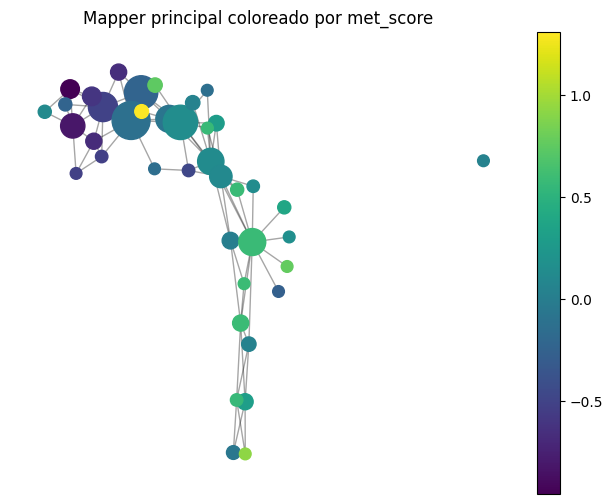

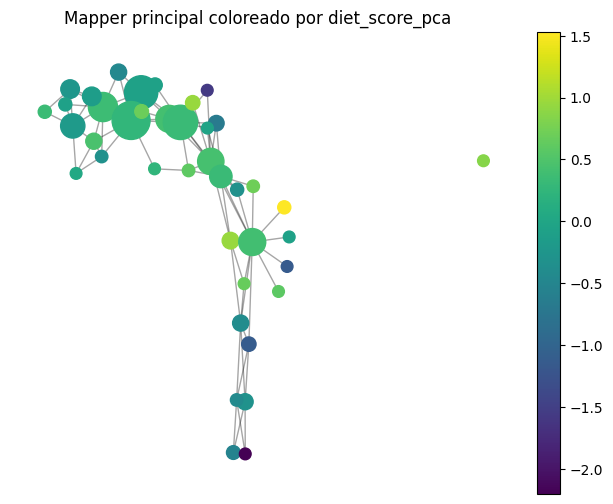

In [ ]:
def node_series_means(graph, sample_series, index):
    vals = {}
    for node, members in graph["nodes"].items():
        ids = index[members]
        vals[node] = sample_series.loc[ids].mean()
    return pd.Series(vals)

def draw_mapper_graph(graph, G, sample_series, title):
    s = sample_series.copy()
    if s.isna().any():
        s = s.fillna(s.median())
    node_vals = node_series_means(graph, s, meta_clean.index)

    pos = nx.spring_layout(G, seed=7)
    node_sizes = np.array([G.nodes[n]["size"] for n in G.nodes()])
    node_colors = np.array([node_vals.loc[n] for n in G.nodes()])

    fig, ax = plt.subplots(figsize=(8, 6))
    nx.draw_networkx_edges(G, pos, ax=ax, alpha=0.35)
    nodes = nx.draw_networkx_nodes(
        G, pos, ax=ax,
        node_size=35 + 9 * node_sizes,
        node_color=node_colors
    )
    plt.colorbar(nodes, ax=ax)
    ax.set_title(title)
    ax.axis("off")
    plt.show()

draw_mapper_graph(graph, G, meta_clean["met_score"], "Mapper principal coloreado por met_score")
draw_mapper_graph(graph, G, meta_clean["diet_score_pca"], "Mapper principal coloreado por diet_score_pca")

### Pregunta 6
Miren el resumen del grafo y las dos coloraciones.

- ¿El grafo parece más bien fragmentado o tiene una estructura principal reconocible?
- ¿Qué variable parece cambiar de manera más ordenada sobre el grafo?
- ¿Cuál de las dos coloraciones cuenta una historia más clara?

### Respuesta del equipo
No parece fragmentado, parece como una línea continua que contiene solo un punto fuera de la conectividad. En cuanto a la coloración, se observa un degradado muy ordenado cuando se usa el met_score. Esta coloración deja muy claro que los puntos ubicados en el la parte baja del espacio topológico tienen un score mucho más bajo (en verde o azul) que los que están en la parte superior (en morado), conformado por la mayor parte de los puntos.

## Parte 6. Medir qué tan bien una variable sigue la estructura

Para comparar variables continuas, usaremos una idea operativa:

- promediamos cada variable por nodo,
- medimos una autocorrelación espacial simple sobre el grafo,
- y la combinamos con el rango de valores entre nodos.

No es una medida sagrada. Es una forma práctica de comparar qué variable parece variar de manera suave y no trivial a lo largo de la estructura.

In [ ]:
def graph_morans_I(G, values):
    nodes = list(G.nodes())
    node_pos = {node: i for i, node in enumerate(nodes)}
    x = values.loc[nodes].values.astype(float)
    n = len(x)
    if n < 3:
        return np.nan
    xbar = x.mean()
    den = ((x - xbar) ** 2).sum()
    if den <= 0:
        return np.nan
    num = 0.0
    W = 0.0
    for u, v in G.edges():
        iu = node_pos[u]
        iv = node_pos[v]
        num += (x[iu] - xbar) * (x[iv] - xbar)
        W += 1.0
    if W == 0:
        return np.nan
    return (n / W) * (num / den)

def graph_edge_stats(G, values):
    nodes = list(G.nodes())
    vals = values.loc[nodes]
    pairs = [(vals[u], vals[v]) for u, v in G.edges()]
    if len(pairs) < 2:
        return {"edge_corr": np.nan, "edge_mad": np.nan}
    a = np.array([p[0] for p in pairs], float)
    b = np.array([p[1] for p in pairs], float)
    return {
        "edge_corr": np.corrcoef(a, b)[0, 1],
        "edge_mad": np.mean(np.abs(a - b)),
    }

def mapper_alignment(sample_series):
    s = sample_series.copy()
    if s.isna().any():
        s = s.fillna(s.median())
    s = (s - s.mean()) / s.std(ddof=0)
    node_vals = node_series_means(graph, s, meta_clean.index)
    I = graph_morans_I(G, node_vals)
    rng = node_vals.max() - node_vals.min()
    estats = graph_edge_stats(G, node_vals)
    return {
        "morans_I": I,
        "node_range": rng,
        "edge_corr": estats["edge_corr"],
        "edge_mad": estats["edge_mad"],
        "alignment_score": I * rng,
    }

In [ ]:
continuous_vars = [
    "met_score", "diet_score_simple", "diet_score_pca",
    "fiber", "per_animal_protein", "per_total_fat", "per_saturated_fat",
    "per_carbohydrates", "age", "bmi", "waist", "HDL",
    "adiponectin", "HOMA_IR", "glucose", "triglycerides", "hsCRP"
]

rows = []
for var in continuous_vars:
    rows.append({"variable": var, **mapper_alignment(meta_clean[var])})

align_df = pd.DataFrame(rows).sort_values("alignment_score", ascending=False)
align_df

,variable,morans_I,node_range,edge_corr,edge_mad,alignment_score
0,met_score,0.505523,1.822053,0.570837,0.301129,0.921090
12,adiponectin,0.456371,1.458955,0.567678,0.236924,0.665825
14,glucose,0.309279,1.909934,0.403224,0.232297,0.590703
11,HDL,0.369121,1.484330,0.518064,0.241783,0.547897
10,waist,0.297611,1.453268,0.360218,0.327313,0.432509
8,age,0.191757,2.012485,0.261245,0.337081,0.385908
15,triglycerides,0.215666,1.625044,0.345628,0.261394,0.350466
9,bmi,0.241740,1.407662,0.304035,0.327482,0.340289
5,per_total_fat,0.155659,2.120191,0.277198,0.281722,0.330026
2,diet_score_pca,0.160341,1.902704,0.266086,0.270827,0.305082


### Pregunta 7
Interpreten la tabla anterior.

- ¿Qué variable parece seguir mejor la estructura del grafo?
- ¿El perfil dietario compite realmente con el perfil cardiometabólico?
- ¿Qué papel parecen jugar las variables clínicas individuales?

### Respuesta del equipo
La variable que mejor sigue la estructura del grafo es la de met_score, pues tiene un alignment score de 0.9; mientras que diet_score_pca solamente tiene un score de 0.3. Esto refuerza que, entre el diet score y el met_score, el met_score describe mucho mejor a los datos en el espacio topológico.

Por su lado, las variables clínicas individuales que más aportan son la de adiponectin, glucosa y colesterol (entre 0.5 y 0.6); estas variables son parte del score cardiometabólico, por lo que refuerza más la idea de que este score describe mejor los datos.

## Parte 7. Test de permutación para las candidatas principales

Ahora vamos a verificar si esa alineación podría deberse al azar.

In [ ]:
rng = np.random.default_rng(42)

def perm_test_alignment(sample_series, n_perm=300):
    obs = mapper_alignment(sample_series)
    s = sample_series.copy().fillna(sample_series.median())
    s = (s - s.mean()) / s.std(ddof=0)

    perm_scores = []
    perm_I = []
    for _ in range(n_perm):
        sp = pd.Series(rng.permutation(s.values), index=s.index)
        node_vals = node_series_means(graph, sp, meta_clean.index)
        I = graph_morans_I(G, node_vals)
        rr = node_vals.max() - node_vals.min()
        perm_scores.append(I * rr)
        perm_I.append(I)

    obs["p_alignment"] = (np.sum(np.array(perm_scores) >= obs["alignment_score"]) + 1) / (n_perm + 1)
    obs["p_moran"] = (np.sum(np.array(perm_I) >= obs["morans_I"]) + 1) / (n_perm + 1)
    obs["perm_alignment_mean"] = float(np.mean(perm_scores))
    obs["perm_alignment_sd"] = float(np.std(perm_scores))
    return obs

In [ ]:
perm_rows = []
for var in ["met_score", "diet_score_pca", "age", "per_total_fat"]:
    perm_rows.append({"variable": var, **perm_test_alignment(meta_clean[var], n_perm=300)})

perm_df = pd.DataFrame(perm_rows)
perm_df

,variable,morans_I,node_range,edge_corr,edge_mad,alignment_score,p_alignment,p_moran,perm_alignment_mean,perm_alignment_sd
0,met_score,0.505523,1.822053,0.570837,0.301129,0.921090,0.003322,0.003322,0.199484,0.157710
1,diet_score_pca,0.160341,1.902704,0.266086,0.270827,0.305082,0.249169,0.299003,0.208459,0.166654
2,age,0.191757,2.012485,0.261245,0.337081,0.385908,0.099668,0.162791,0.188189,0.146305
3,per_total_fat,0.155659,2.120191,0.277198,0.281722,0.330026,0.136213,0.242525,0.173402,0.160935


### Pregunta 8
A partir de esta tabla, expliquen:

- ¿Qué variable tiene la evidencia más fuerte de seguir la estructura del grafo?
- ¿Qué variable parece tener una señal más débil o ambigua?
- ¿Qué concluyen ahora sobre la segunda pregunta central del proyecto?

### Respuesta del equipo


Al realizar la permutación, el cual tiene como propósito observar si la continuidad se obtuvo de forma aleatoria o si al hacer cambios aleatorios sigue manteniendo secuencia y sentido. Para analizar si tiene significancia estadística, se busca obtener un valor_p de alignment que sea menor a 0.05, esto significa que es poco probable encontrar una mejor continuidad si fuera aleatoria la secuencia.
Observando el valor p del score cardiometabólico, se puede interpreta que es la variable que tiene la mayor evidencia a seguir la estructura del grafo, mientras que el score dietario si obtuvo un valor p alto, indicando que al hacer cambios aleatorios pierde fuerza y no muestra continuidad.

Con esto se concluye que la composición de la microbioma está más relacionada con el estado de salud cardiometabólica que con el comportamiento dietario del paciente.

## Parte 8. Interpretar extremos de la estructura

Si una variable realmente organiza el grafo, entonces sus extremos deberían corresponder a regiones con diferencias clínicas y microbiológicas interpretables.

En esta parte usaremos el grafo para identificar extremos del continuo.

In [ ]:
sample_to_nodes = {i: [] for i in range(len(meta_clean))}
for node, members in graph["nodes"].items():
    for m in members:
        sample_to_nodes[m].append(node)

def sample_smoothed(graph, sample_series):
    s = sample_series.copy().fillna(sample_series.median())
    node_vals = node_series_means(graph, s, meta_clean.index)
    vals = []
    for i in range(len(meta_clean)):
      nodes = sample_to_nodes[i]
      vals.append(node_vals.loc[nodes].mean() if nodes else np.nan)
    return pd.Series(vals, index=meta_clean.index)

def compare_extremes(smoothed_series, quant=0.2):
    s = smoothed_series.dropna()
    low_thr = s.quantile(quant)
    high_thr = s.quantile(1 - quant)
    low_ids = s[s <= low_thr].index
    high_ids = s[s >= high_thr].index
    return low_ids, high_ids

sm_met = sample_smoothed(graph, meta_clean["met_score"])
sm_diet = sample_smoothed(graph, meta_clean["diet_score_pca"])

low_met, high_met = compare_extremes(sm_met, quant=0.2)
low_diet, high_diet = compare_extremes(sm_diet, quant=0.2)

print("Extremos del continuo cardiometabólico:", len(low_met), len(high_met))
print("Extremos del continuo dietario:", len(low_diet), len(high_diet))

Extremos del continuo cardiometabólico: 70 63
Extremos del continuo dietario: 63 66


In [ ]:
vars_compare = [
    "met_score", "diet_score_pca", "fiber", "per_total_fat", "per_carbohydrates",
    "per_animal_protein", "age", "bmi", "waist", "HDL", "adiponectin",
    "glucose", "triglycerides", "HOMA_IR", "hsCRP"
]

def table_extremes(low_ids, high_ids):
    rows = []
    for var in vars_compare:
        s = meta_clean[var].copy().fillna(meta_clean[var].median())
        low = s.loc[low_ids]
        high = s.loc[high_ids]
        _, p = mannwhitneyu(low, high, alternative="two-sided")
        rows.append({
            "variable": var,
            "mean_low": low.mean(),
            "mean_high": high.mean(),
            "diff_high_minus_low": high.mean() - low.mean(),
            "p": p,
        })
    return pd.DataFrame(rows).sort_values("p")

print("Extremos del continuo cardiometabólico")
display(table_extremes(low_met, high_met))

print("Extremos del continuo dietario")
display(table_extremes(low_diet, high_diet))

Extremos del continuo cardiometabólico


,variable,mean_low,mean_high,diff_high_minus_low,p
0,met_score,-0.557261,0.624050,1.181311,7.335198e-08
10,adiponectin,7.576714,5.373175,-2.203540,1.714740e-05
8,waist,87.442857,98.612698,11.169841,1.750114e-05
9,HDL,50.371429,41.682540,-8.688889,7.616418e-05
11,glucose,84.085714,94.126984,10.041270,2.056092e-04
13,HOMA_IR,2.239814,3.280545,1.040731,2.102081e-04
7,bmi,26.570000,29.858730,3.288730,6.619567e-04
12,triglycerides,124.942857,165.666667,40.723810,1.504409e-02
14,hsCRP,3.127571,4.011746,0.884175,2.027190e-02
2,fiber,17.000000,18.285714,1.285714,1.763392e-01


Extremos del continuo dietario


,variable,mean_low,mean_high,diff_high_minus_low,p
4,per_carbohydrates,54.061111,56.675152,2.614040,0.000003
1,diet_score_pca,-0.703527,0.763460,1.466987,0.000012
3,per_total_fat,29.552540,27.735606,-1.816934,0.000063
6,age,36.666667,41.984848,5.318182,0.008348
13,HOMA_IR,2.873112,3.998515,1.125403,0.050820
5,per_animal_protein,63.709524,62.020152,-1.689372,0.058838
11,glucose,87.666667,90.272727,2.606061,0.196947
14,hsCRP,2.792222,3.109242,0.317020,0.235919
10,adiponectin,6.609683,6.537727,-0.071955,0.313289
12,triglycerides,133.666667,150.984848,17.318182,0.360652


### Pregunta 9
Comparen ambas tablas.

- ¿Qué diferencias aparecen entre los extremos del continuo cardiometabólico?
- ¿Qué diferencias aparecen entre los extremos del continuo dietario?
- ¿Cuál de los dos continuos produce contrastes biológicos más nítidos?

### Respuesta del equipo
Las personas en el extremo alto del score cardiometabólico tienen mayor BMI, trigliceridos más altos, un HOMA-IR más alto (indica resistencia a la insulina), un hsCRP más alto (inflamación en el cuerpo más alta), y HDL (el colesterol "bueno") más bajo.
Pero las variables relacionadas a la dieta (diet score, proteína, carbs, etc.) no tuvieron mayor diferencia en estos extremos.


Por otro lado, en el extremo del perfil dietario mostraron un porcentaje mayor de carbohidratos, menos grasa total, entre otros, pero con un p score bajo.


Comparando ambos perfiles, el cardiometabólico muestra un contraste mucho más nítido (9 variables con un p-value significativo). Tomando en cuenta estos hallazgos con la parte anterior, se ve cómo el score metabólico sigue siendo superior ante el dietario, más coherente, marcado y mejor segmentando hacia los pacientes.

## Parte 9. Géneros que distinguen extremos

Esto es exploratorio. No reemplaza un análisis diferencial completo, pero ayuda a ver si los extremos del continuo muestran diferencias microbiológicas interpretables.

In [ ]:
gen_prev = (X_rel > 0).mean(axis=0)
common_genera = gen_prev[gen_prev >= 0.10].index.tolist()

def fdr_bh(pvals):
    p = np.asarray(pvals, dtype=float)
    n = len(p)
    order = np.argsort(p)
    ranks = np.arange(1, n + 1)
    q = np.empty(n)
    q[order] = p[order] * n / ranks
    q_sorted = q[order]
    q_sorted = np.minimum.accumulate(q_sorted[::-1])[::-1]
    q[order] = np.minimum(q_sorted, 1.0)
    return q

def top_genus_diffs(group1_ids, group2_ids):
    rows = []
    for g in common_genera:
        a = X_rel.loc[group1_ids, g]
        b = X_rel.loc[group2_ids, g]
        mean_a = a.mean()
        mean_b = b.mean()
        log2fc = np.log2((mean_b + 1e-6) / (mean_a + 1e-6))
        _, p = mannwhitneyu(a, b, alternative="two-sided")
        rows.append({
            "genus": g,
            "mean_group1": mean_a,
            "mean_group2": mean_b,
            "log2FC_group2_vs_group1": log2fc,
            "p": p,
        })
    out = pd.DataFrame(rows)
    out["q"] = fdr_bh(out["p"].values)
    return out.sort_values(["q", "p"])

print("Continuo cardiometabólico: grupo 2 = extremo alto")
display(top_genus_diffs(low_met, high_met).head(15))

print("Continuo dietario: grupo 2 = extremo alto")
display(top_genus_diffs(low_diet, high_diet).head(15))

Continuo cardiometabólico: grupo 2 = extremo alto


,genus,mean_group1,mean_group2,log2FC_group2_vs_group1,p,q
0,02d06,0.013006,0.001429,-3.185025,4.584338e-15,6.326387e-13
7,Akkermansia,0.155143,0.008653,-4.164106,9.626490e-15,6.642278e-13
98,Prevotella,0.016237,0.198418,3.611146,2.863156e-14,1.317052e-12
43,Dehalobacterium,0.001078,0.000201,-2.416549,5.762500e-11,1.988063e-09
127,Unassigned,0.073327,0.032341,-1.180955,2.009341e-10,5.545781e-09
62,Haemophilus,0.000448,0.012506,4.798297,1.056685e-09,2.430376e-08
51,Enterobacter,0.006471,0.076314,3.559753,2.450675e-09,4.831331e-08
32,Christensenella,0.000413,0.000223,-0.886679,3.008640e-09,5.189904e-08
86,Oscillospira,0.057949,0.027234,-1.089323,9.286884e-09,1.304781e-07
100,Propionispora,0.023936,0.002332,-3.359189,9.454937e-09,1.304781e-07


Continuo dietario: grupo 2 = extremo alto


,genus,mean_group1,mean_group2,log2FC_group2_vs_group1,p,q
74,Megasphaera,0.000788,0.002058,1.383158,0.000170,0.023521
53,Escherichia,0.039717,0.133128,1.744956,0.000358,0.024716
21,Bilophila,0.000337,0.000745,1.142292,0.007109,0.221339
30,Catenibacterium,0.005078,0.011710,1.205323,0.007857,0.221339
41,Cytophagales,0.000019,0.000007,-1.322020,0.008120,0.221339
86,Oscillospira,0.033293,0.055069,0.726002,0.009623,0.221339
69,Lactobacillus,0.000514,0.001041,1.016652,0.015910,0.254733
46,Desulfonema,0.000019,0.000035,0.860254,0.016371,0.254733
134,[Prevotella],0.003906,0.006172,0.660019,0.016613,0.254733
25,Butyricicoccus,0.002132,0.001886,-0.176834,0.018799,0.257788


### Pregunta 10
Miren los géneros que distinguen los extremos.

- ¿El continuo cardiometabólico y el dietario producen patrones microbiológicos igual de claros?
- ¿Hay géneros que parezcan especialmente asociados con uno de los extremos?
- ¿Qué interpretación biológica proponen, sin exagerar?

### Respuesta del equipo
El perfil cardiometabólico tiene valores de p y q mucho más relevantes que los del perfil dietario- mostrando que las diferencias entre los extremos son más sigificativas con el score metabólico que el dietario. Esto sí coincide con las últimas partes, recalcando patrones de que el score cardiometabólico sí cambia en los extremos y el dietario no, o al menos no tanto.

Sí hay genéros que parecen especialmente asociados con un extremo: 02d06, Akkermansia, Prevotella y Dehalobacterium en el score cardiometabólico muestran grandes diferencias en los extremos.

El género de Akkermansia se ha relacionado con mayor integridad de la barrera intestinal y mejor sensibilidad a la insulina, aunque la dirección causal no está establecida. Por otro lado, es común que pacientes con diabetes tipo 2 tengan niveles elevados de 02d06.

## Parte 10. Control geométrico: CLR a nivel de género

No queremos que toda la interpretación dependa de una sola geometría.

In [ ]:
X_pc = genus_counts + 0.5
X_comp = X_pc.div(X_pc.sum(axis=1), axis=0)
logX = np.log(X_comp.values)
X_clr = logX - logX.mean(axis=1, keepdims=True)

coords_clr = PCA(n_components=10).fit_transform(StandardScaler().fit_transform(X_clr))
X_clr5 = StandardScaler().fit_transform(coords_clr[:, :5])
lens_clr = coords_clr[:, :2]
lens_clr = (lens_clr - lens_clr.min(axis=0)) / (lens_clr.max(axis=0) - lens_clr.min(axis=0))

graph_clr = mapper.map(
    lens=lens_clr,
    X=X_clr5,
    cover=km.Cover(n_cubes=10, perc_overlap=0.35),
    clusterer=DBSCAN(eps=1.0, min_samples=4),
)
G_clr = graph_to_nx(graph_clr)

def mapper_alignment_on(graph_obj, G_obj, sample_series):
    s = sample_series.copy().fillna(sample_series.median())
    s = (s - s.mean()) / s.std(ddof=0)
    node_vals = node_series_means(graph_obj, s, meta_clean.index)
    I = graph_morans_I(G_obj, node_vals)
    rng = node_vals.max() - node_vals.min()
    estats = graph_edge_stats(G_obj, node_vals)
    return {
        "morans_I": I,
        "node_range": rng,
        "edge_corr": estats["edge_corr"],
        "edge_mad": estats["edge_mad"],
        "alignment_score": I * rng,
    }

clr_rows = []
for var in ["met_score", "diet_score_pca", "age", "per_total_fat"]:
    clr_rows.append({"variable": var, **mapper_alignment_on(graph_clr, G_clr, meta_clean[var])})

pd.DataFrame(clr_rows).sort_values("alignment_score", ascending=False)

,variable,morans_I,node_range,edge_corr,edge_mad,alignment_score
0,met_score,0.334865,1.834360,0.553790,0.224584,0.614264
2,age,0.189430,2.038688,0.450356,0.221421,0.386189
1,diet_score_pca,0.107565,1.707746,0.166412,0.278194,0.183694
3,per_total_fat,0.053544,1.803845,0.091039,0.274554,0.096586


### Pregunta 11
Usen esta tabla como control metodológico.

- ¿La señal principal se sostiene cuando cambian la geometría?
- ¿Qué se mantiene?
- ¿Qué se debilita?

### Respuesta del equipo
Se mantiene que el score cardiometabólico es el principal descriptor.

Se debilita la relación de todos los índices en general, pero principalmente el diet score y el porcentage de grasa pierden fuerza.

Se refuerza la teoría de que el score cardiometabólico se adapta mejor a la estructura microbiologica de los pacientes.

## Parte 11. Explorar otros caminos posibles

Hasta aquí ya siguieron el camino principal del proyecto. Ahora cada equipo debe explorar **al menos un camino alterno** a partir de esta base.

La idea no es que “encuentren algo espectacular” a la fuerza. La idea es probar una pregunta razonable adicional y decidir, con evidencia, si ese camino:

- agrega información útil,
- no cambia mucho la historia principal,
- o simplemente no funciona bien para estos datos.

Eso también es un buen resultado.

### Sugerencias de caminos alternos

Pueden escoger uno de estos caminos, o proponer otro con la aprobación de su profesor:

1. **Cambiar el lente de Mapper**, manteniendo Bray--Curtis a nivel de género.  
   Ejemplo: usar `PCoA1 + PCoA2` en lugar de `PCoA1 + densidad local`.

2. **Cambiar la geometría**, manteniendo el nivel taxonómico.  
   Ejemplo: usar Jaccard sobre presencia/ausencia a nivel de género.

3. **Cambiar la escala taxonómica**.  
   Ejemplo: repetir el análisis a nivel de familia.

4. **Cambiar la pregunta biológica**.  
   Ejemplo: explorar si `age`, `medicament`, `stool_consistency` o alguna otra variable continua/categórica sigue mejor la estructura que las ya analizadas.

5. **Construir una variante razonable de un score**.  
   Ejemplo: redefinir el perfil dietario o cardiometabólico y comparar si la historia cambia.

### Regla importante

No se evalúa que el camino alterno “salga bien”.  
Se evalúa que:

- esté bien justificado,
- se ejecute con cuidado,
- y se interprete con honestidad.

In [ ]:
# Herramientas para la exploración alterna

def normalize_cols(A):
    A = np.asarray(A, dtype=float)
    mn = A.min(axis=0)
    mx = A.max(axis=0)
    den = np.where(mx > mn, mx - mn, 1.0)
    return (A - mn) / den

def build_mapper_graph(X_for_mapper, lens_matrix, n_cubes=10, perc_overlap=0.35, eps=1.0, min_samples=4):
    mapper_local = km.KeplerMapper(verbose=0)
    graph_obj = mapper_local.map(
        lens=normalize_cols(lens_matrix),
        X=X_for_mapper,
        cover=km.Cover(n_cubes=n_cubes, perc_overlap=perc_overlap),
        clusterer=DBSCAN(eps=eps, min_samples=min_samples),
    )
    G_obj = graph_to_nx(graph_obj)

    covered = set()
    for members in graph_obj["nodes"].values():
        covered.update(members)

    summary_obj = pd.Series({
        "nodes": G_obj.number_of_nodes(),
        "edges": G_obj.number_of_edges(),
        "components": nx.number_connected_components(G_obj) if G_obj.number_of_nodes() else np.nan,
        "covered_samples_fraction": len(covered) / len(meta_clean),
        "giant_component_fraction_of_nodes": (
            max(len(c) for c in nx.connected_components(G_obj)) / G_obj.number_of_nodes()
            if G_obj.number_of_nodes() else np.nan
        ),
    })
    return graph_obj, G_obj, summary_obj

def draw_mapper_graph_on(graph_obj, G_obj, sample_series, title):
    s = sample_series.copy()
    if s.isna().any():
        s = s.fillna(s.median())
    node_vals = node_series_means(graph_obj, s, meta_clean.index)

    pos = nx.spring_layout(G_obj, seed=7)
    node_sizes = np.array([G_obj.nodes[n]["size"] for n in G_obj.nodes()])
    node_colors = np.array([node_vals.loc[n] for n in G_obj.nodes()])

    fig, ax = plt.subplots(figsize=(8, 6))
    nx.draw_networkx_edges(G_obj, pos, ax=ax, alpha=0.35)
    nodes = nx.draw_networkx_nodes(
        G_obj, pos, ax=ax,
        node_size=35 + 9 * node_sizes,
        node_color=node_colors
    )
    plt.colorbar(nodes, ax=ax)
    ax.set_title(title)
    ax.axis("off")
    plt.show()

def mapper_alignment_on_graph(graph_obj, G_obj, sample_series):
    s = sample_series.copy()
    if s.isna().any():
        s = s.fillna(s.median())
    s = (s - s.mean()) / s.std(ddof=0)
    node_vals = node_series_means(graph_obj, s, meta_clean.index)
    I = graph_morans_I(G_obj, node_vals)
    rng = node_vals.max() - node_vals.min()
    estats = graph_edge_stats(G_obj, node_vals)
    return {
        "morans_I": I,
        "node_range": rng,
        "edge_corr": estats["edge_corr"],
        "edge_mad": estats["edge_mad"],
        "alignment_score": I * rng,
    }


# tabla completa con p-values (CLR control)
rng_clr = np.random.default_rng(42)

def perm_test_on_graph(graph_obj, G_obj, sample_series, n_perm=300):
    obs = mapper_alignment_on_graph(graph_obj, G_obj, sample_series)
    s = sample_series.copy().fillna(sample_series.median())
    s = (s - s.mean()) / s.std(ddof=0)
    perm_scores = []
    perm_I = []
    for _ in range(n_perm):
        sp = pd.Series(rng_clr.permutation(s.values), index=s.index)
        node_vals = node_series_means(graph_obj, sp, meta_clean.index)
        I = graph_morans_I(G_obj, node_vals)
        rr = node_vals.max() - node_vals.min()
        perm_scores.append(I * rr)
        perm_I.append(I)
    obs["p_alignment"] = (np.sum(np.array(perm_scores) >= obs["alignment_score"]) + 1) / (n_perm + 1)
    obs["p_moran"]     = (np.sum(np.array(perm_I)     >= obs["morans_I"])          + 1) / (n_perm + 1)
    obs["perm_alignment_mean"] = float(np.mean(perm_scores))
    obs["perm_alignment_sd"]   = float(np.std(perm_scores))
    return obs

### Opción A. Cambiar el lente de Mapper

Prueben el mismo análisis principal, pero usando otro lente. Un primer experimento razonable es usar `PCoA1 + PCoA2` en lugar de `PCoA1 + densidad local`.

La pregunta es:

**¿la historia principal se mantiene, se debilita o cambia de manera importante cuando cambian el lente?**

Resumen del experimento A


,0
nodes,55.000000
edges,119.000000
components,4.000000
covered_samples_fraction,0.804933
giant_component_fraction_of_nodes,0.909091


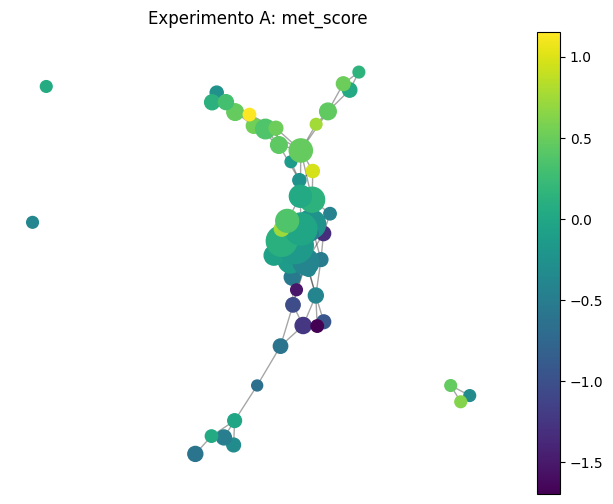

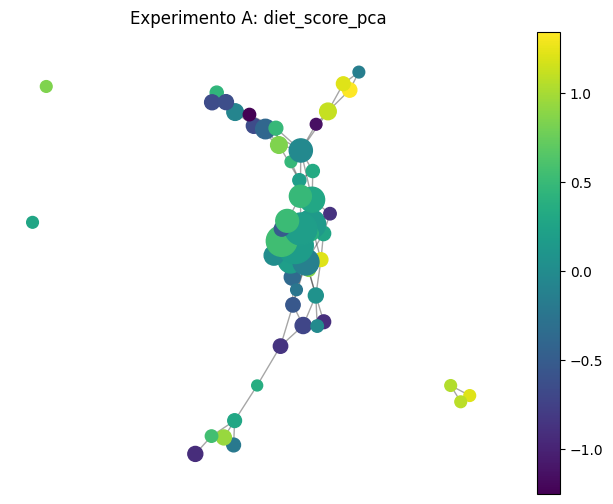

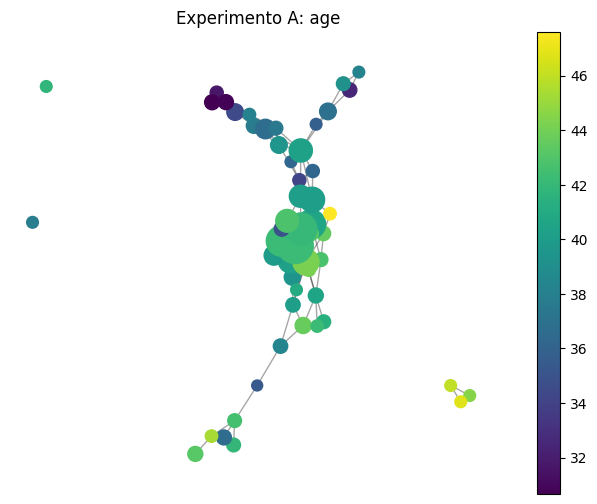

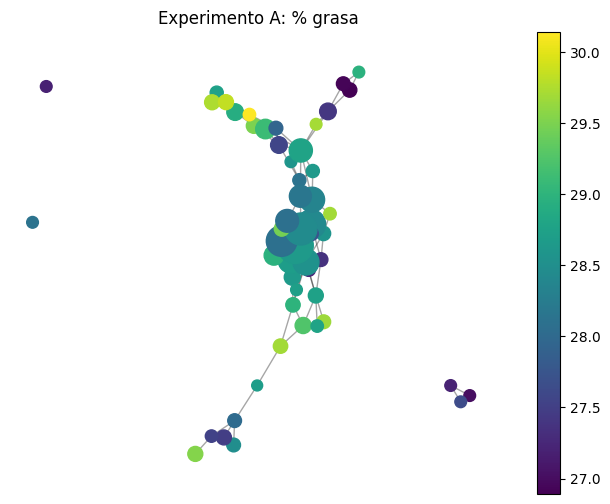

,variable,morans_I,node_range,edge_corr,edge_mad,alignment_score,p_alignment,p_moran,perm_alignment_mean,perm_alignment_sd
0,met_score,0.334865,1.834360,0.553790,0.224584,0.614264,0.006645,0.013289,0.213685,0.140540
1,diet_score_pca,0.107565,1.707746,0.166412,0.278194,0.183694,0.534884,0.607973,0.200468,0.136281
2,age,0.189430,2.038688,0.450356,0.221421,0.386189,0.086379,0.202658,0.193932,0.138520
3,per_total_fat,0.053544,1.803845,0.091039,0.274554,0.096586,0.720930,0.774086,0.193291,0.142440


In [ ]:
# Opción A: Bray--Curtis a nivel de género, pero con lente PCoA1 + PCoA2

lens_alt_A = coords_bray[:, :2]
graph_A, G_A, summary_A = build_mapper_graph(
    X_for_mapper=X_bray5,
    lens_matrix=lens_alt_A,
    n_cubes=10,
    perc_overlap=0.35,
    eps=1.0,
    min_samples=4,
)

print("Resumen del experimento A")
display(summary_A)

draw_mapper_graph_on(graph_A, G_A, meta_clean["met_score"], "Experimento A: met_score")
draw_mapper_graph_on(graph_A, G_A, meta_clean["diet_score_pca"], "Experimento A: diet_score_pca")
draw_mapper_graph_on(graph_A, G_A, meta_clean["age"], "Experimento A: age")
draw_mapper_graph_on(graph_A, G_A, meta_clean["per_total_fat"], "Experimento A: % grasa")


rows_A = []
for var in ["met_score", "diet_score_pca", "age", "per_total_fat"]:
    rows_A.append({"variable": var, **mapper_alignment_on_graph(graph_A, G_A, meta_clean[var])})

pd.DataFrame(rows_A).sort_values("alignment_score", ascending=False)

# nueva tablita
clr_vars = ["met_score", "diet_score_pca", "age", "per_total_fat"]
clr_rows = []
for var in clr_vars:
    if var in meta_clean.columns:
        clr_rows.append({"variable": var,
                         **perm_test_on_graph(graph_clr, G_clr, meta_clean[var])})

clr_perm_df = pd.DataFrame(clr_rows)
display(clr_perm_df)

### Opción B. Cambiar la geometría

Prueben una geometría distinta y observen si la estructura sigue contando una historia parecida.

Un experimento razonable es usar **Jaccard** sobre presencia/ausencia a nivel de género.

La pregunta es:

**¿la historia principal se sostiene cuando ya no usamos abundancias relativas, sino solo presencia/ausencia?**

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/pairwise.py:2466: DataConversionWarning: Data was converted to boolean for metric jaccard
  warnings.warn(msg, DataConversionWarning)


Resumen del experimento B


,0
nodes,42.000000
edges,69.000000
components,6.000000
covered_samples_fraction,0.547085
giant_component_fraction_of_nodes,0.857143


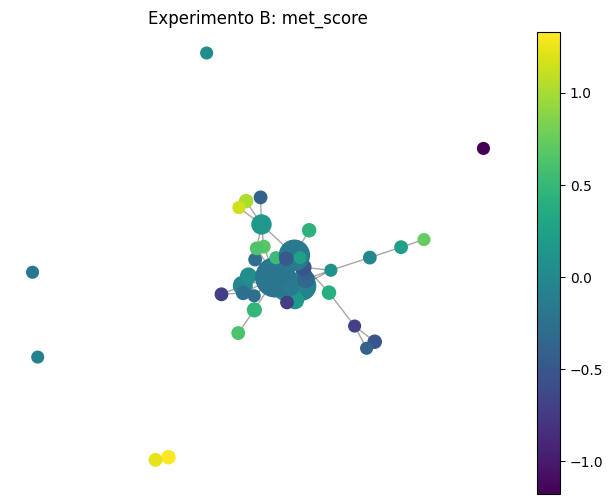

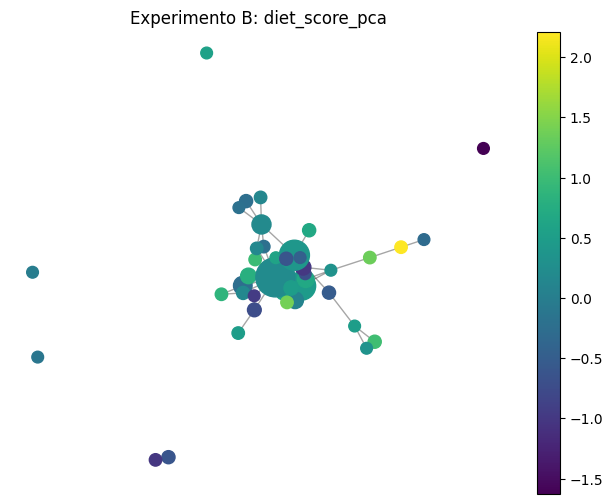

,variable,morans_I,node_range,edge_corr,edge_mad,alignment_score,p_alignment,p_moran,perm_alignment_mean,perm_alignment_sd
0,met_score,0.259700,2.020268,0.403198,0.306432,0.524664,0.142857,0.159468,0.318077,0.180730
1,diet_score_pca,0.133180,1.956710,0.199511,0.327570,0.260595,0.544850,0.637874,0.311433,0.193378
2,age,0.147054,2.052219,0.218138,0.410680,0.301787,0.481728,0.524917,0.306332,0.178503
3,per_total_fat,0.121211,1.553379,0.177569,0.295042,0.188287,0.760797,0.704319,0.327328,0.197562


In [ ]:
# Opción B: Jaccard a nivel de género (presencia/ausencia)

X_bin = (X_rel > 0).astype(int)
D_jacc = pairwise_distances(X_bin.values, metric="jaccard")
coords_jacc, eig_jacc = pcoa(D_jacc, 10)

X_jacc5 = StandardScaler().fit_transform(coords_jacc[:, :5])
density_jacc = knn_density(X_jacc5, 15)
lens_jacc = np.c_[coords_jacc[:, 0], density_jacc]

graph_B, G_B, summary_B = build_mapper_graph(
    X_for_mapper=X_jacc5,
    lens_matrix=lens_jacc,
    n_cubes=10,
    perc_overlap=0.35,
    eps=1.0,
    min_samples=4,
)

print("Resumen del experimento B")
display(summary_B)

draw_mapper_graph_on(graph_B, G_B, meta_clean["met_score"], "Experimento B: met_score")
draw_mapper_graph_on(graph_B, G_B, meta_clean["diet_score_pca"], "Experimento B: diet_score_pca")

rows_B = []
for var in ["met_score", "diet_score_pca", "age", "per_total_fat"]:
    rows_B.append({"variable": var, **mapper_alignment_on_graph(graph_B, G_B, meta_clean[var])})

pd.DataFrame(rows_B).sort_values("alignment_score", ascending=False)


# nueva tablita
clr_vars = ["met_score", "diet_score_pca", "age", "per_total_fat"]
clr_rows = []
for var in clr_vars:
    if var in meta_clean.columns:
        clr_rows.append({"variable": var,
                         **perm_test_on_graph(graph_B, G_B, meta_clean[var])})

clr_perm_df = pd.DataFrame(clr_rows)
display(clr_perm_df)

resumen del experimento B


,0
nodes,25.000000
edges,43.000000
components,5.000000
covered_samples_fraction,0.695067
giant_component_fraction_of_nodes,0.760000


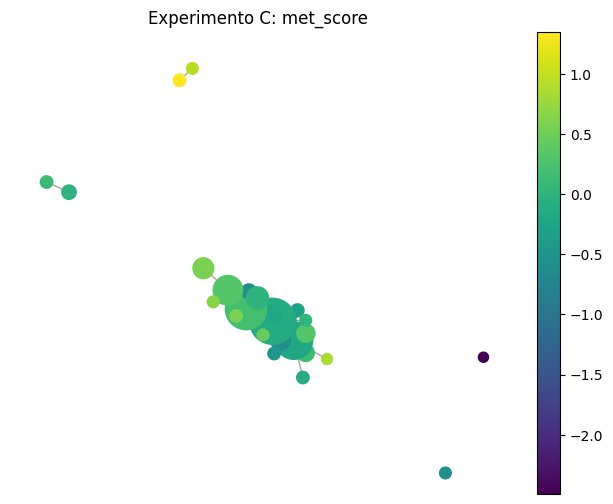

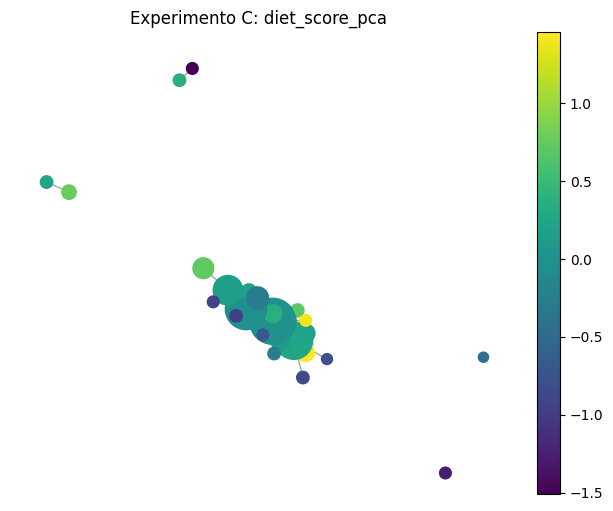

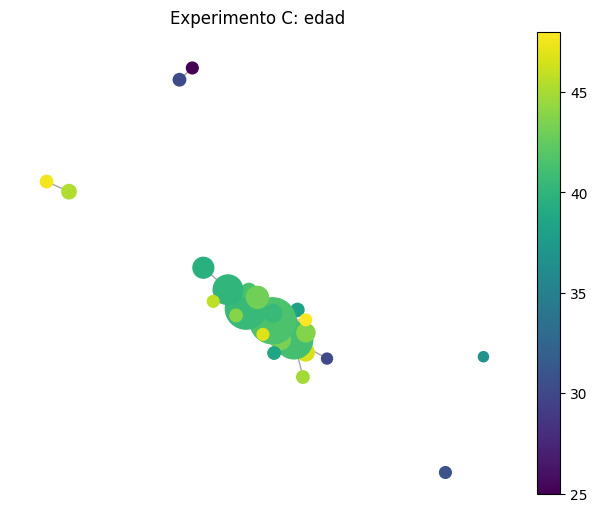

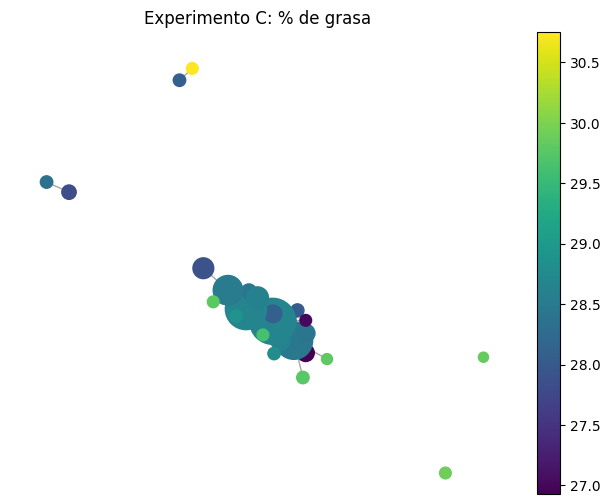

,variable,morans_I,node_range,edge_corr,edge_mad,alignment_score,p_alignment,p_moran,perm_alignment_mean,perm_alignment_sd
0,met_score,0.334865,1.834360,0.553790,0.224584,0.614264,0.013289,0.016611,0.192147,0.140911
1,diet_score_pca,0.107565,1.707746,0.166412,0.278194,0.183694,0.461794,0.541528,0.190943,0.144041
2,age,0.189430,2.038688,0.450356,0.221421,0.386189,0.096346,0.205980,0.192955,0.137913
3,per_total_fat,0.053544,1.803845,0.091039,0.274554,0.096586,0.760797,0.823920,0.204576,0.147248


In [ ]:
# opción B: CLR + Aitchison (geometría composicional alternativa)

# transformación CLR
X_pc_B = genus_counts + 0.5
X_comp_B = X_pc_B.div(X_pc_B.sum(axis=1), axis=0)
logX_B = np.log(X_comp_B.values)
X_clr_B = logX_B - logX_B.mean(axis=1, keepdims=True)

# reducción de dimensión (PCA sobre CLR)
coords_clr_B = PCA(n_components=10).fit_transform(
    StandardScaler().fit_transform(X_clr_B)
)
X_clr5_B = StandardScaler().fit_transform(coords_clr_B[:, :5])

# lente: PC1 + densidad kNN
density_clr_B = knn_density(X_clr5_B, 15)
lens_clr_B = np.c_[coords_clr_B[:, 0], density_clr_B]

# mapper
graph_B, G_B, summary_B = build_mapper_graph(
    X_for_mapper=X_clr5_B,
    lens_matrix=lens_clr_B,
    n_cubes=10,
    perc_overlap=0.35,
    eps=1.0,
    min_samples=4,
)

print("resumen del experimento B")
display(summary_B)

draw_mapper_graph_on(graph_B, G_B, meta_clean["met_score"],     "Experimento C: met_score")
draw_mapper_graph_on(graph_B, G_B, meta_clean["diet_score_pca"], "Experimento C: diet_score_pca")
draw_mapper_graph_on(graph_B, G_B, meta_clean["age"], "Experimento C: edad")
draw_mapper_graph_on(graph_B, G_B, meta_clean["per_total_fat"], "Experimento C: % de grasa")



# alignment scores
rows_B = []
for var in ["met_score", "diet_score_pca", "age", "per_total_fat"]:
    rows_B.append({"variable": var, **mapper_alignment_on_graph(graph_B, G_B, meta_clean[var])})

pd.DataFrame(rows_B).sort_values("alignment_score", ascending=False)

# nueva tablita
clr_vars = ["met_score", "diet_score_pca", "age", "per_total_fat"]
clr_rows = []
for var in clr_vars:
    if var in meta_clean.columns:
        clr_rows.append({"variable": var,
                         **perm_test_on_graph(graph_clr, G_clr, meta_clean[var])})

clr_perm_df = pd.DataFrame(clr_rows)
display(clr_perm_df)

### Pregunta 12

Documenten aquí el camino alterno que exploraron.

Expliquen:

1. **Qué cambiaron** respecto al análisis principal.  
2. **Por qué ese cambio parecía razonable**.  
3. **Qué encontraron**.  
4. **Si ese camino refuerza, debilita o no cambia mucho la historia principal**.  
5. **Si el resultado fue débil o fallido, por qué sigue siendo informativo**.

### Respuesta del equipo
1. En la opción A cambia el lente, en lugar de usar el PCoA1 y la densidad local se usan ambos PCoA (el primero y el segundo). Esto cambia el enfoque a que se busca un grafo que represente la varianza, pero no la densidad de los datos. Por otro lado, en la opción B cambia la geometría, de Bray a CLR y a Jaccard

2. Este cambio fue razonable porque se busca ver qué tan válido es el resultado preeliminar con la geometría y lente originales. Al comparar ambas opciones, el grafo de la opción A tenía mucha más forma que el B y, en la opción A los meta/diet scores se veían más alineados con el análisis preeliminar.

3. El hallazgo principal es que el met score sí está relacionado con la estructura microbiológica, pues tiene un gradiente continuo a lo largo del grafo y valores que aparentan una relación fuerte con la estructura metabólica (morans I altos, rango de nodo alto, etc)- sin embargo, se encontró que esta relación no es tan fuerte como lo parece en el análisis preeliminar.

4. Refuerza la historia en parte, pues el met score sigue siendo el predominante al compararse con el score dietético. El morans I de la edad subió considerablemente en la opción A (otro lente), y al dibujar el grafo por edad sí se ve un gradiente marcado- aunque el p value no necesariamente respalda esta teoría. En la opción B (otra geometría) se ve como la relación estructura microbiológica/score cardiometabólico no es tan fuerte como parece, aunque sigue siendo válida.

5. El resultado de que el met score es relevante es fuerte, pero el resultado de que la edad tenga algo que ver no lo es tanto. Si bien con este lente cobra relevancia, en el análisis anterior no lo fue tanto, por lo que no se podrían sacar conclusiones relacionadas a la edad todavía.

## Parte 12. Conclusión final

Redacten una conclusión de entre 10 y 15 líneas que responda, con claridad y prudencia, estas preguntas:

1. ¿El microbioma en esta cohorte se organiza mejor como grupos separados o como una estructura continua?
2. ¿Qué cambia de manera más clara al recorrer esa estructura?
3. ¿Qué diferencias aparecen entre regiones o extremos?
4. ¿Qué interpretación biológica les parece razonable?
5. ¿Qué conclusión sería exagerada o injustificada?
6. ¿Qué les enseñó el camino alterno que exploraron, incluso si no funcionó bien?

### Conclusión del equipo
1. Como una estructura continua
2. El índice cardiometabólico
3. Las personas en el extremo alto del score cardiometabólico tienen mayor BMI, trigliceridos más altos, un HOMA-IR más alto (indica resistencia a la insulina), un hsCRP más alto (inflamación en el cuerpo más alta), y HDL (el colesterol "bueno") más bajo. Los géneros 02d06, Akkermansia y dehalobacterium tienen valores mayores cuando el índice cardiometabólico es menor.  En el caso de la prevotella, crece junto al íncide cardiometabólico.

4. Además de ver que sí hay una variación significativa en la microbioma de cada paciente- o sea confirmar que todos tienen distintos perfiles microbiológicos; se encontró que un género alto de Akkermansia se ha relacionado con mayor integridad de la barrera intestinal y mejor sensibilidad a la insulina, además de asociarce de forma positiva con la salud metabólica y la integridad de la mucosa. Por otro lado, niveles elevados de 02d06 y de prevotella son símbolo de inflamación. Se puede intuir entonces que personas con un íncide cardiometabólico menor (o sea más "sanas") tienen una mejor combinación de genus. Es decir, que personas con trigliceridos altos, BMI alto, HOMA-IR alto, hsCRP alto y HDL bajos tienen mayor prescencia de prevotella y 02d06 (asociados inflamación, diabetes tipo 2, consumo alto de azúcares, etc.)- aunque tengan mejores valores de akkermensia, asociado con buena barrera intestinal y salud metabólica.

5. Sería exagerado concluir que uno causa el otro, o que la dieta no tiene nada que ver con la salud cardiometabólica. Además, no consideramos que sea correcto todavía generalizar por edad ni por sexo ni por otras variables categóricas; pues son aspectos en los que no se profundizaron en este proyecto pero que sí pudieran ser relevantes en la práctica.

6. Se encontró que la relación del metscore con la estructura microbiológica no es tan fuerte como pudiera parecer en el análisis principal- pero sí existe. Además se vio que la edad sí podría tener una relación con la salud cardiometabólica; pero solo es una teoría que habría que explorar con más detalle.

## Nota metodológica final

No se espera que concluyan causalidad.  
Se espera que produzcan asociaciones razonadas, bien apoyadas por la geometría, la topología y las variables observadas.

#Rutas Alternativas

## Análisis Exploratorio

Variables numéricas: 27
Variables no numéricas: 7

Numéricas:
['age', 'HDL', 'LDL', 'cholesterol', 'triglycerides', 'hsCRP', 'glucose', 'glycosylated_hg', 'adiponectin', 'insulin', 'HOMA_IR', 'systolic_bp', 'diastolic_bp', 'bmi', 'body_fat', 'waist', 'fiber', 'per_protein', 'per_animal_protein', 'per_total_fat', 'per_saturated_fat', 'per_monoinsaturated_fat', 'per_polyunsaturated_fat', 'per_carbohydrates', 'met_score', 'diet_score_simple', 'diet_score_pca']

No numéricas:
['city', 'sex', 'age_range', 'stool_consistency', 'hiden_blood', 'bmi_class', 'medicament']


city
Medellin        101
Barranquilla     90
Cali             90
Bogota           86
Bucaramanga      79
Name: count, dtype: int64


sex
Female    231
Male      215
Name: count, dtype: int64


age_range
41_62    237
18_40    209
Name: count, dtype: int64


bmi_class
Overweight    171
Lean          140
Obese         135
Name: count, dtype: int64


/usr/local/lib/python3.12/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(



===== DATASET: meta y género =====


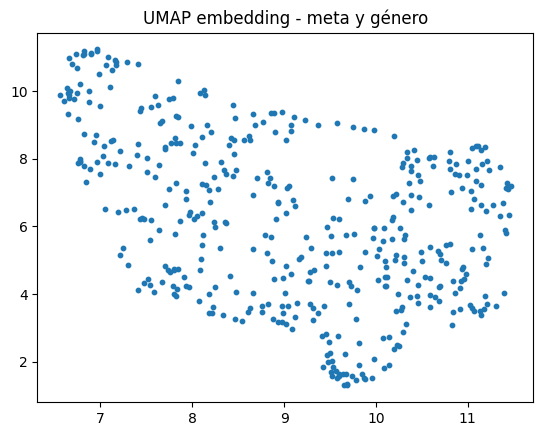

Top H1 persistences:
[0.88175878 0.55853865 0.39883026 0.37907913 0.37278765 0.36837754
 0.33581451 0.26862887 0.21078125 0.20721525]


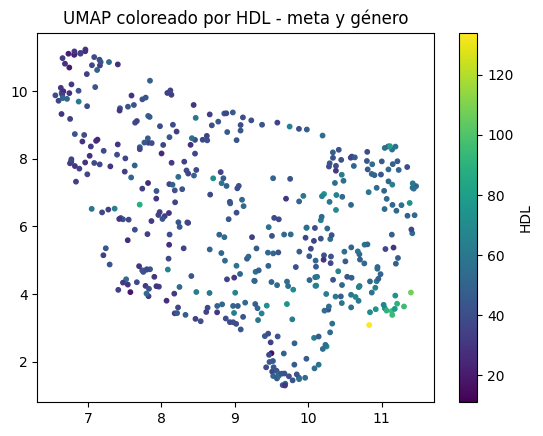

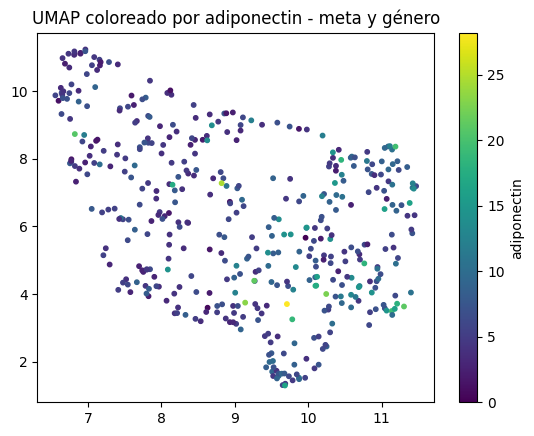

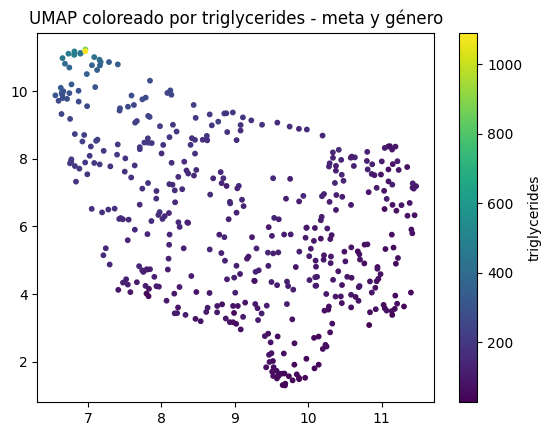

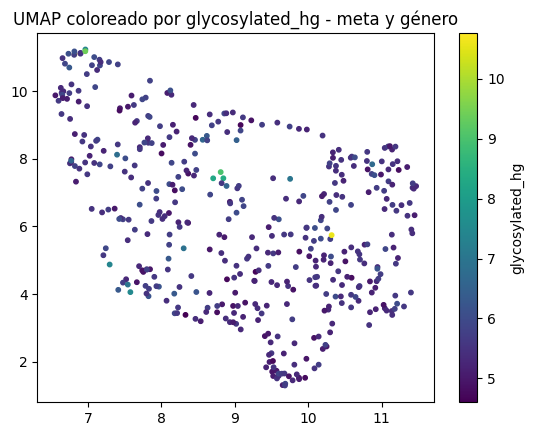

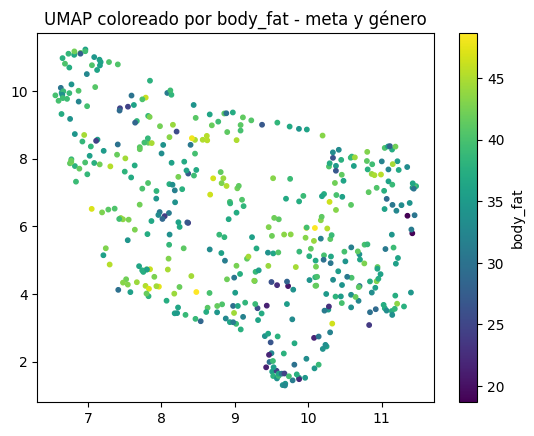

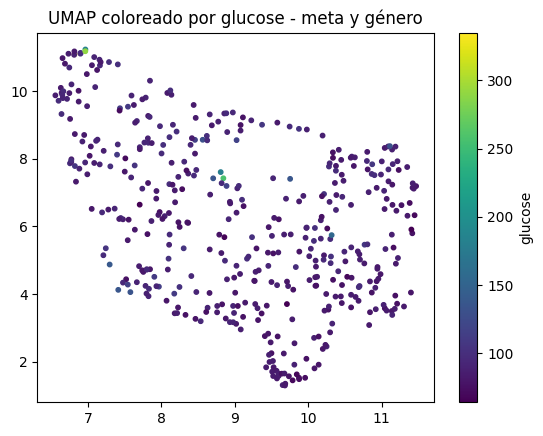

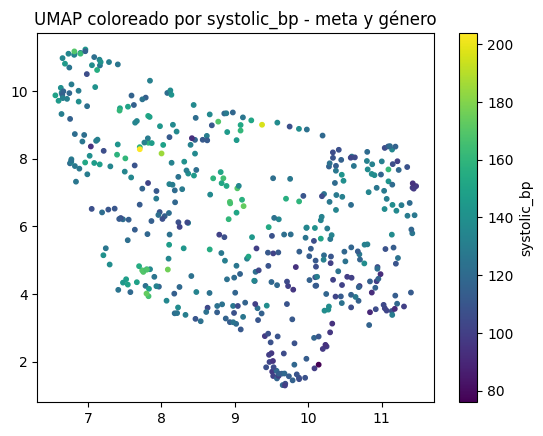

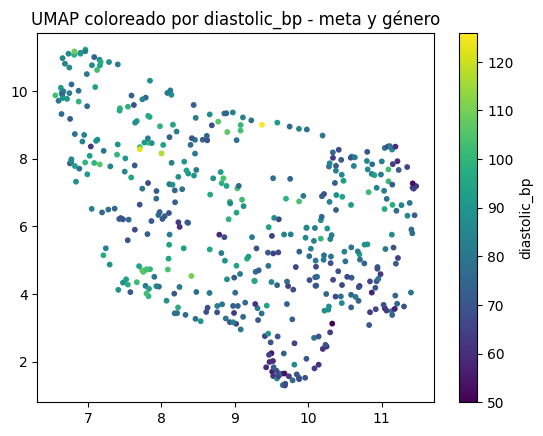

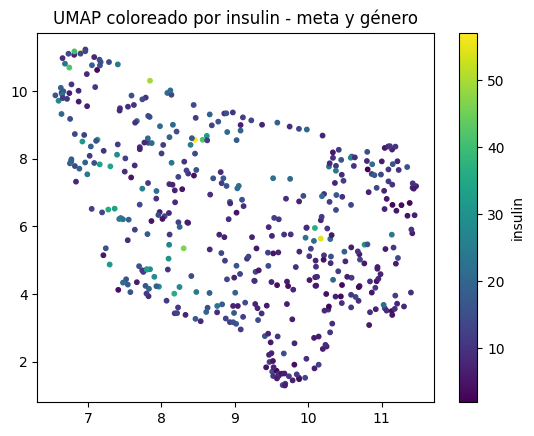

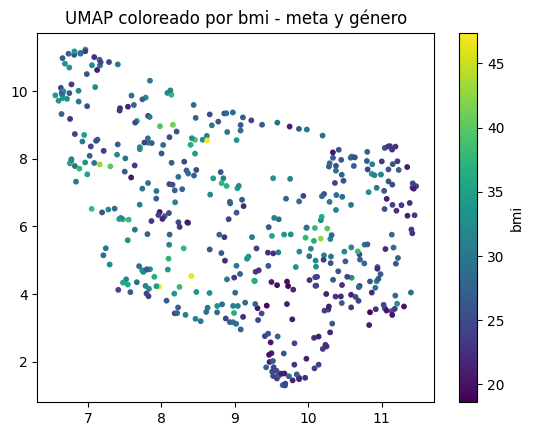

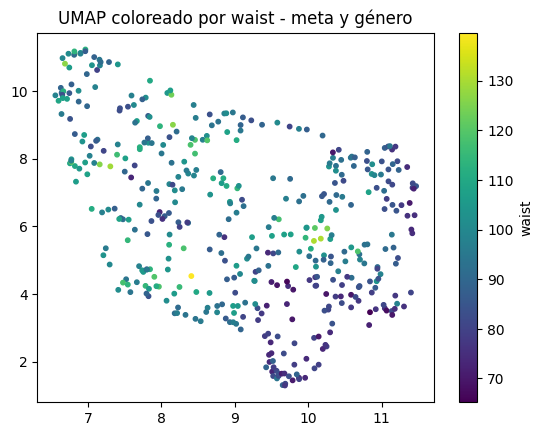

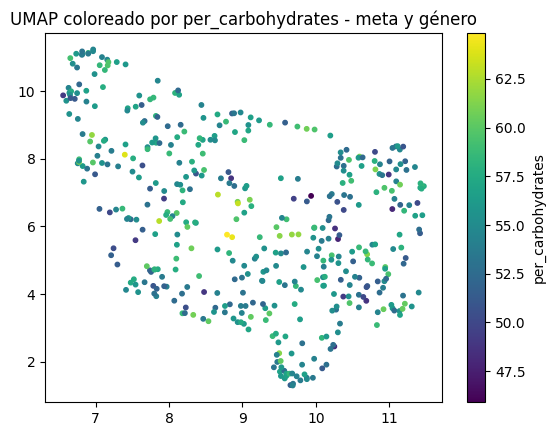

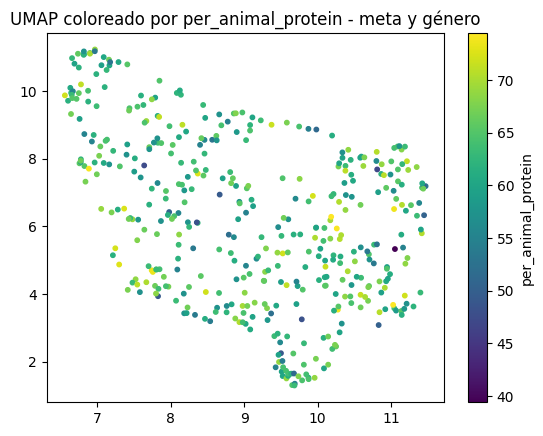

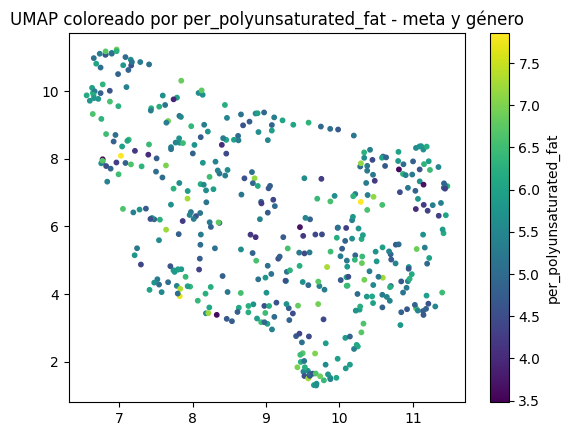

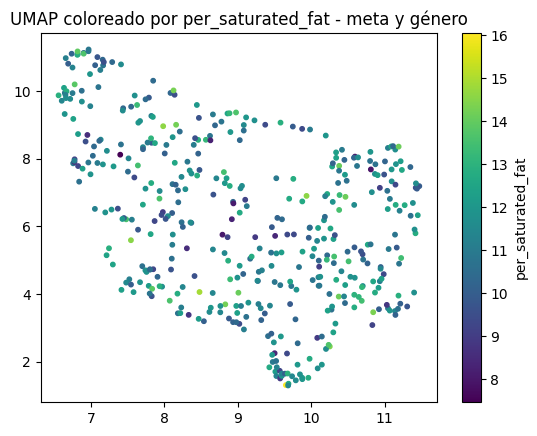

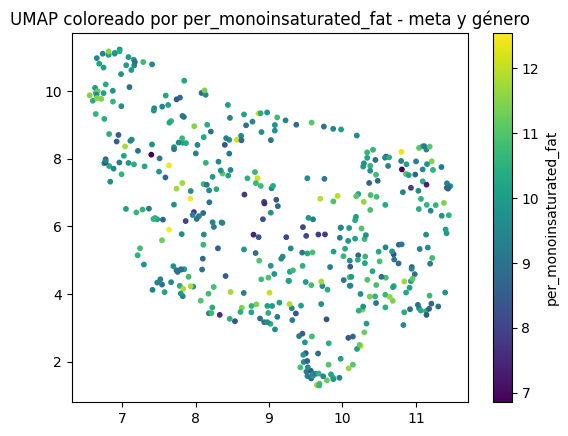

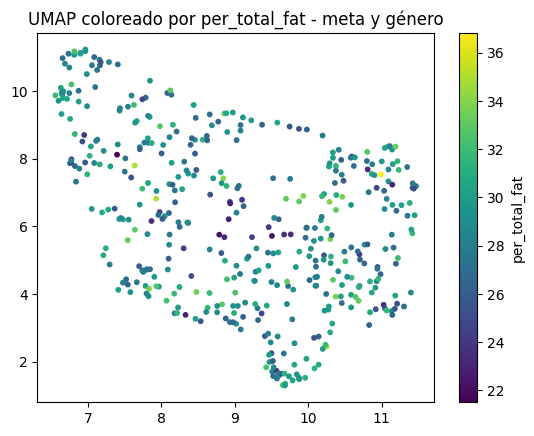

In [ ]:
missing = meta_clean.isna().sum().sort_values(ascending=False)
missing[missing > 0]

numeric_cols = meta_clean.select_dtypes(include=np.number).columns.tolist()
categorical_cols = [c for c in meta_clean.columns if c not in numeric_cols]

print("Variables numéricas:", len(numeric_cols))
print("Variables no numéricas:", len(categorical_cols))
print("\nNuméricas:")
print(numeric_cols)
print("\nNo numéricas:")
print(categorical_cols)

for col in ["city", "sex", "age_range", "bmi_class"]:
    print("\n")
    print(meta_clean[col].value_counts())

meta_num = meta_clean[numeric_cols].copy()
meta_num = meta_num.fillna(meta_num.median())

vars_to_plot = [
    "HDL",
    "adiponectin",
    "triglycerides",
    "glycosylated_hg",
    "body_fat",
    "glucose",
    "systolic_bp",
    "diastolic_bp",
    "insulin",
    "bmi",
    "waist",
    "per_carbohydrates",
    "per_animal_protein",
    "per_polyunsaturated_fat",
    "per_saturated_fat",
    "per_monoinsaturated_fat",
    "per_total_fat",
]

# UMAP
reducer = umap.UMAP(
  n_neighbors=15,
  min_dist=0.1,
  n_components=2,
  metric='braycurtis',
  random_state=42
)
X_umap = reducer.fit_transform(meta_num)

print(f"\n===== DATASET: meta y género =====")

# Gráfica UMAP
plt.figure()
plt.scatter(X_umap[:, 0], X_umap[:, 1], s=10)
plt.title(f"UMAP embedding - meta y género")
plt.show()

# Homología Persistente sobre embedding
dgms_umap = ripser(X_umap)['dgms']

# H1 persistencias
if len(dgms_umap) > 1 and len(dgms_umap[1]) > 0:
  dgm1 = dgms_umap[1]
  pers_H1 = dgm1[:, 1] - dgm1[:, 0]
  pers_sorted = np.sort(pers_H1)[::-1]

  print("Top H1 persistences:")
  print(pers_sorted[:10])
else:
  print("No H1 features detected")

#Gráfica de UMAP coloreado por variables
for var in vars_to_plot:
  col = (
    meta_num[var]
    .astype(str)
    .str.replace(",", ".", regex=False)
    .astype(float)
  )

  plt.figure()

  plt.scatter(
    X_umap[:, 0],
    X_umap[:, 1],
    c=col.values,
    cmap='viridis',
    s=10
  )

  plt.colorbar(label=var)
  plt.title(f"UMAP coloreado por {var} - meta y género")

  plt.show()


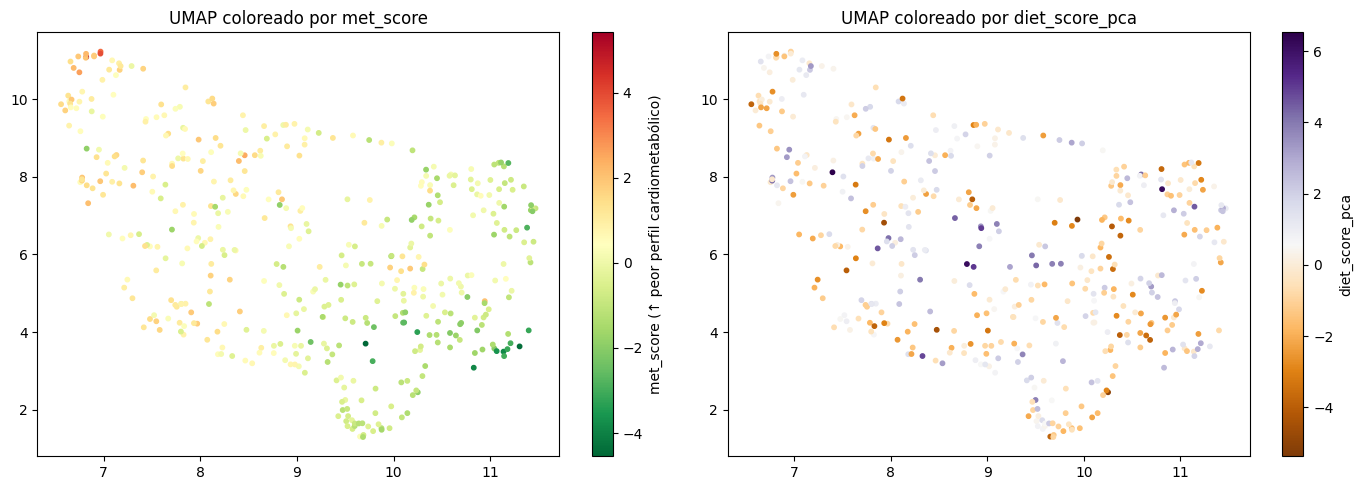

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# met_score
sc1 = axes[0].scatter(
    X_umap[:, 0], X_umap[:, 1],
    c=meta_clean["met_score"].values,
    cmap='RdYlGn_r',
    s=10
)
plt.colorbar(sc1, ax=axes[0], label="met_score (↑ peor perfil cardiometabólico)")
axes[0].set_title("UMAP coloreado por met_score")

# diet_score_simple
sc2 = axes[1].scatter(
    X_umap[:, 0], X_umap[:, 1],
    c=meta_clean["diet_score_pca"].values,
    cmap='PuOr',
    s=10
)
plt.colorbar(sc2, ax=axes[1], label="diet_score_pca")
axes[1].set_title("UMAP coloreado por diet_score_pca")

plt.tight_layout()
plt.show()

#UMAP coloreado por variables categóricas

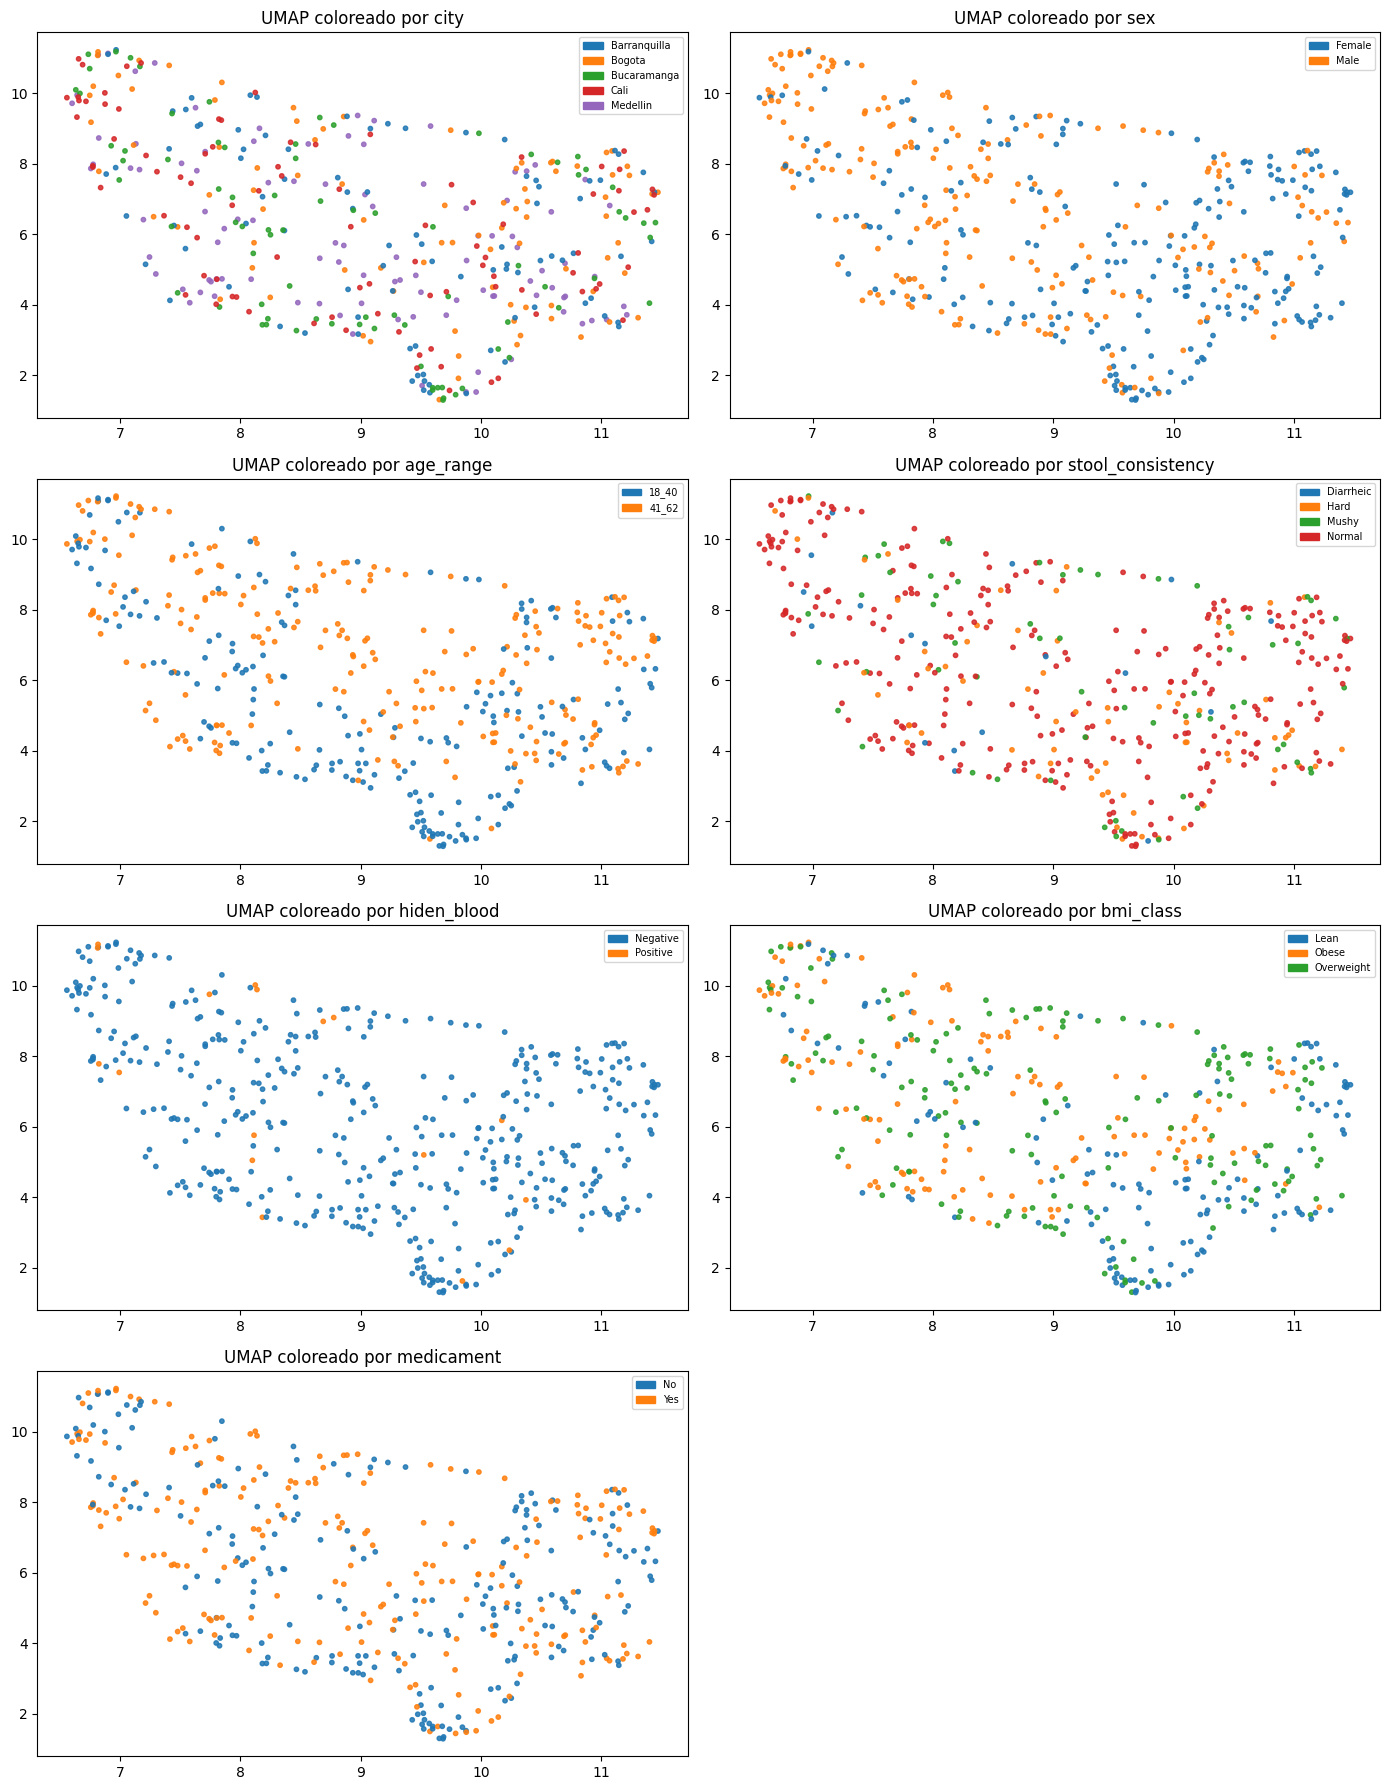

In [ ]:
cat_vars = ["city", "sex", "age_range", "stool_consistency", "hiden_blood", "bmi_class", "medicament"]

# Paleta cualitativa
palette = plt.get_cmap("tab10")

n_vars = len(cat_vars)
ncols = 2
nrows = (n_vars + 1) // ncols  # 4 filas

fig, axes = plt.subplots(nrows, ncols, figsize=(14, nrows * 4.5))
axes = axes.flatten()

for i, var in enumerate(cat_vars):
    col = meta_clean[var].astype(str)
    categories = sorted(col.unique())
    cat_to_int = {c: j for j, c in enumerate(categories)}
    colors = col.map(cat_to_int).values

    sc = axes[i].scatter(
        X_umap[:, 0], X_umap[:, 1],
        c=colors,
        cmap=palette,
        vmin=0, vmax=max(9, len(categories) - 1),
        s=10,
        alpha=0.85
    )
    axes[i].set_title(f"UMAP coloreado por {var}")

    # Leyenda discreta
    patches = [
        mpatches.Patch(color=palette(cat_to_int[c] / max(9, len(categories) - 1)), label=c)
        for c in categories
    ]
    axes[i].legend(handles=patches, fontsize=7, loc="best", markerscale=1.2)

# Ocultar subplot vacío si n_vars es impar
if n_vars % ncols != 0:
    axes[-1].set_visible(False)

plt.tight_layout()
plt.show()

#Experimento 1 (Mapper con Bray5)

/usr/local/lib/python3.12/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


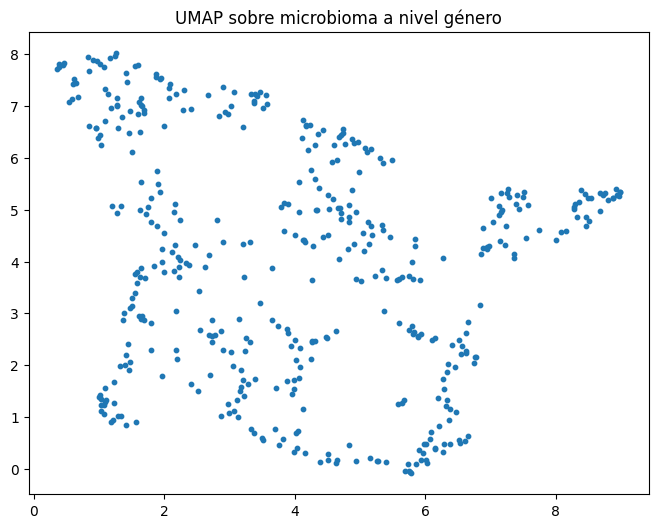

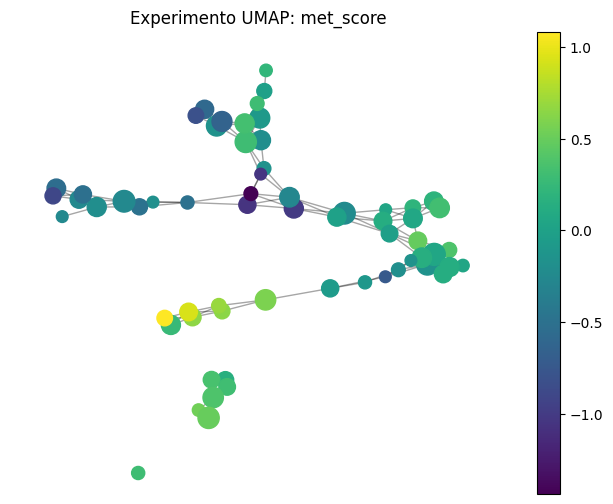

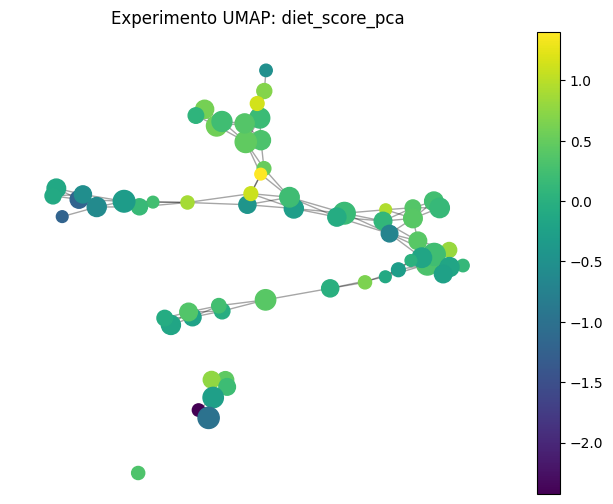

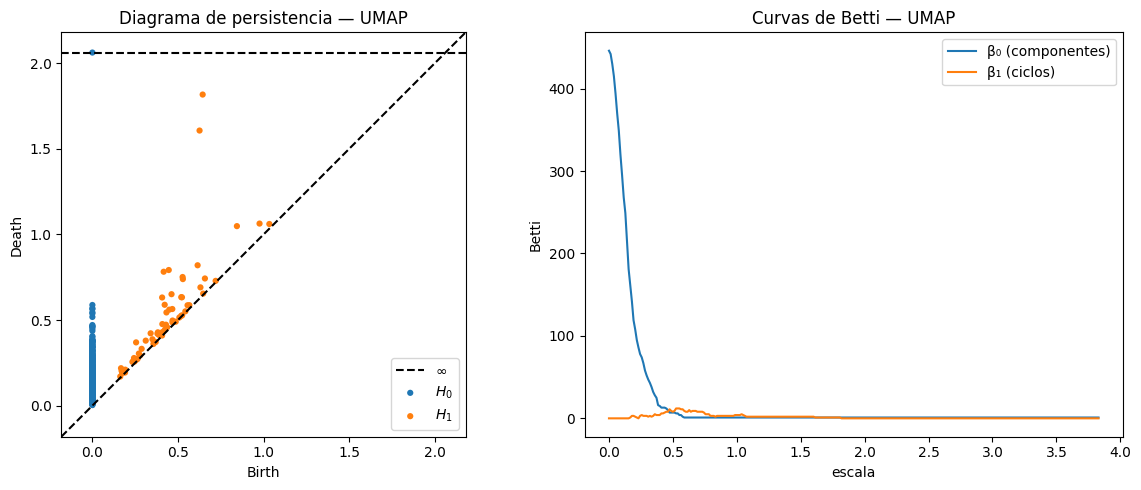

β₁ total: 62
β₁ con persistencia > 0.1: 16
Persistencia máxima β₁: 1.1734
Persistencia mediana β₁: 0.0324


In [ ]:
embedding = UMAP(n_components=2, random_state=42).fit_transform(X_bray5)
lens_umap = (embedding - embedding.min(axis=0)) / (embedding.max(axis=0) - embedding.min(axis=0))

graph_umap = mapper.map(
    lens=lens_umap,
    X=X_bray5,
    cover=km.Cover(n_cubes=10, perc_overlap=0.35),
    clusterer=DBSCAN(eps=1.0, min_samples=4),
)
G_umap = graph_to_nx(graph_umap)

# Visualización del embedding
plt.figure(figsize=(8, 6))
plt.scatter(embedding[:, 0], embedding[:, 1], s=10)
plt.title("UMAP sobre microbioma a nivel género")
plt.show()

# Grafo Mapper coloreado
draw_mapper_graph_on(graph_umap, G_umap, meta_clean["met_score"], "Experimento UMAP: met_score")
draw_mapper_graph_on(graph_umap, G_umap, meta_clean["diet_score_pca"], "Experimento UMAP: diet_score_pca")

# Alignment scores
rows_umap = []
for var in ["met_score", "diet_score_pca", "age", "per_total_fat"]:
    rows_umap.append({"variable": var, **mapper_alignment_on(graph_umap, G_umap, meta_clean[var])})

pd.DataFrame(rows_umap).sort_values("alignment_score", ascending=False)


# Calcular homología persistente sobre el embedding UMAP
ph_umap = ripser(embedding, maxdim=1)
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Diagrama de persistencia
plot_diagrams(ph_umap["dgms"], ax=axes[0], show=False)
axes[0].set_title("Diagrama de persistencia — UMAP")

# Curvas de Betti
scales = np.linspace(0, np.percentile(embedding, 95) * 0.5, 300)

def betti_curve(dgm, scales):
    curve = np.zeros(len(scales))
    for i, s in enumerate(scales):
        curve[i] = np.sum((dgm[:, 0] <= s) & (dgm[:, 1] > s))
    return curve

b0_umap = betti_curve(ph_umap["dgms"][0], scales)
b1_umap = betti_curve(ph_umap["dgms"][1], scales)

axes[1].plot(scales, b0_umap, label="β₀ (componentes)")
axes[1].plot(scales, b1_umap, label="β₁ (ciclos)")
axes[1].set_xlabel("escala")
axes[1].set_ylabel("Betti")
axes[1].set_title("Curvas de Betti — UMAP")
axes[1].legend()

plt.tight_layout()
plt.show()

# Resumen numérico
dgm1_umap = ph_umap["dgms"][1]
persistence_umap = dgm1_umap[:, 1] - dgm1_umap[:, 0]
print(f"β₁ total: {len(dgm1_umap)}")
print(f"β₁ con persistencia > 0.1: {(persistence_umap > 0.1).sum()}")
print(f"Persistencia máxima β₁: {persistence_umap.max():.4f}")
print(f"Persistencia mediana β₁: {np.median(persistence_umap):.4f}")

#Experimento B (Espacio: Bray5 y Lente: UMAP0 + Densidad Local)

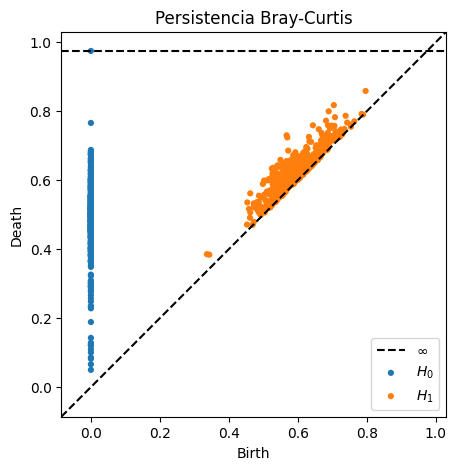

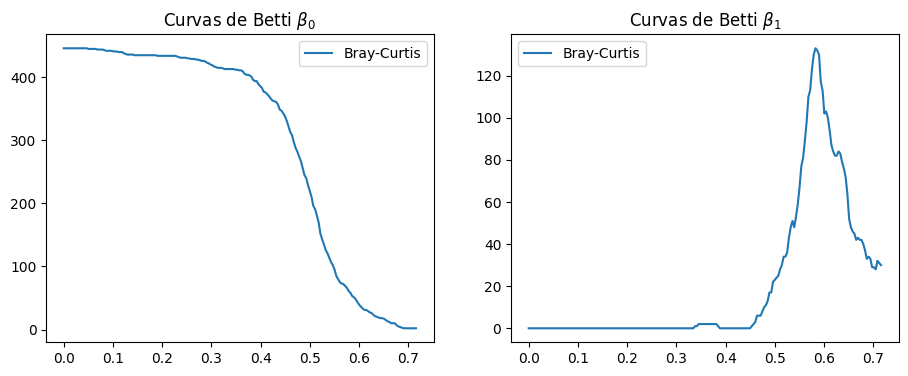


Resumen topológico:


,geometry,max_persistence_beta0,median_persistence_beta0,max_persistence_beta1,median_persistence_beta1,n_beta1_bars,n_beta1_persistence_gt_0.20
0,Bray-Curtis,0.766177,0.497362,0.162526,0.026011,477,0



Top persistencias H1 Bray-Curtis:


,birth,death,persistence
0,0.567729,0.730255,0.162526
1,0.569741,0.724101,0.154361
2,0.643830,0.759249,0.115420
3,0.572284,0.685810,0.113526
4,0.704547,0.817834,0.113287
5,0.689612,0.799770,0.110159
6,0.549719,0.659145,0.109426
7,0.524818,0.633801,0.108983
8,0.528518,0.636100,0.107583
9,0.541194,0.643067,0.101872


/usr/local/lib/python3.12/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


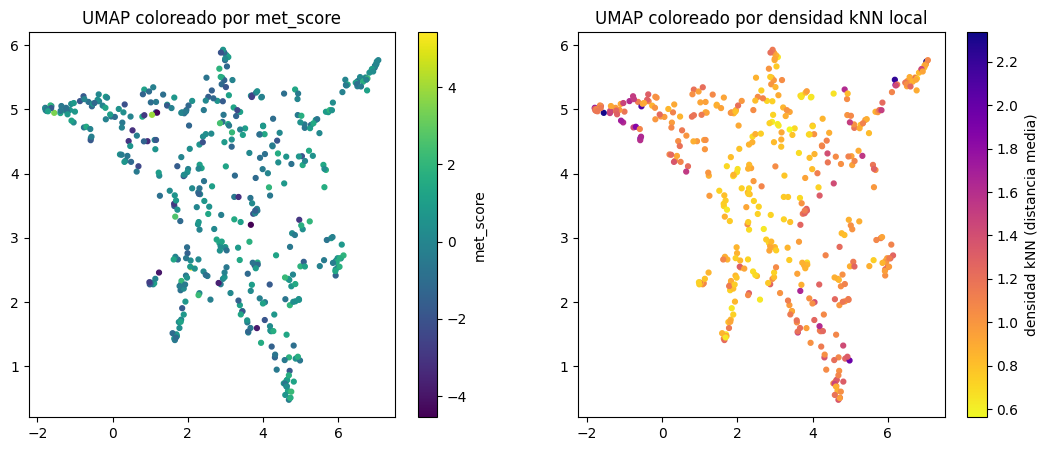


Resumen del grafo Mapper (Exp B):
{'nodes': 34, 'edges': 67, 'components': 3, 'covered_samples_fraction': 0.6748878923766816, 'giant_component_fraction_of_nodes': 0.9117647058823529}


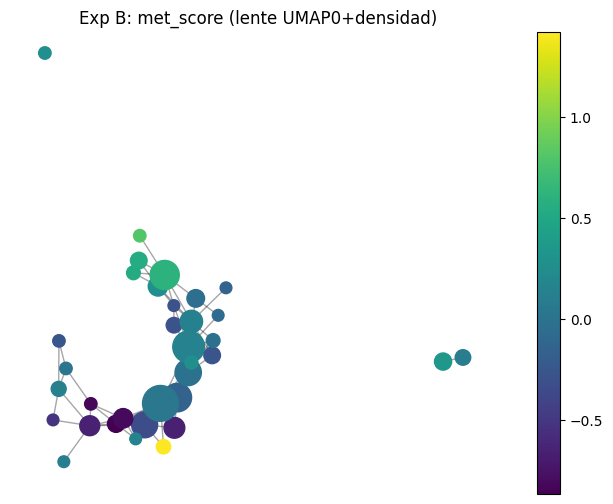

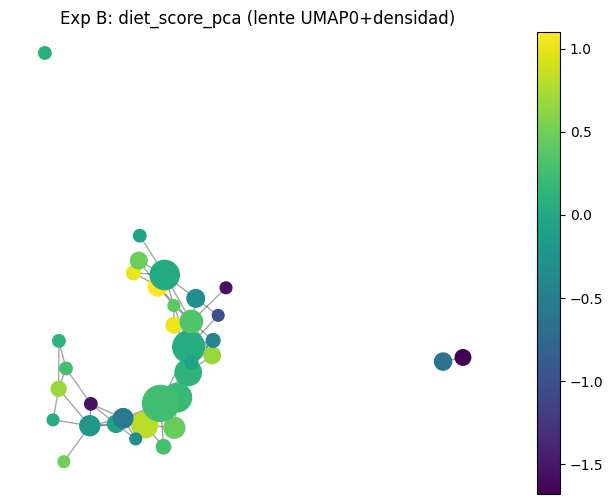


Alignment scores (Exp B — lente UMAP0+densidad):


,variable,morans_I,node_range,edge_corr,edge_mad,alignment_score
0,met_score,0.354152,1.839569,0.424684,0.292623,0.651487
9,HOMA_IR,0.218770,2.240399,0.370732,0.268852,0.490131
14,per_animal_protein,0.237420,2.051998,0.317471,0.308385,0.487185
6,adiponectin,0.371997,1.274642,0.484481,0.286150,0.474162
8,triglycerides,0.246310,1.463347,0.349579,0.257467,0.360437
4,waist,0.238473,1.281080,0.260328,0.310812,0.305503
1,diet_score_pca,0.209776,1.418238,0.278875,0.277936,0.297513
11,fiber,0.106732,2.443833,0.215705,0.311013,0.260835
5,HDL,0.219575,1.160256,0.233956,0.277201,0.254763
12,per_total_fat,0.173989,1.415455,0.276151,0.227371,0.246273



Test de permutación (Exp B):


,variable,morans_I,node_range,edge_corr,edge_mad,alignment_score,p_alignment,p_moran,perm_alignment_mean,perm_alignment_sd
0,met_score,0.354152,1.839569,0.424684,0.292623,0.651487,0.019934,0.016611,0.199178,0.168619
1,diet_score_pca,0.209776,1.418238,0.278875,0.277936,0.297513,0.292359,0.205980,0.210605,0.173983
2,age,0.170596,1.185941,0.220129,0.296260,0.202316,0.485050,0.315615,0.200983,0.163642
3,per_total_fat,0.173989,1.415455,0.276151,0.227371,0.246273,0.335548,0.275748,0.201030,0.179077



Extremos continuo cardiometabólico: 65 bajo / 62 alto

Extremos del continuo cardiometabólico (Exp B):


,variable,mean_low,mean_high,diff_high_minus_low,p
0,met_score,-0.749347,0.641180,1.390527,2.117471e-08
10,adiponectin,8.747077,5.173710,-3.573367,2.174879e-06
9,HDL,51.800000,42.322581,-9.477419,3.012823e-04
8,waist,87.464615,97.248387,9.783772,3.175145e-04
14,hsCRP,2.206000,3.262097,1.056097,1.052181e-03
11,glucose,84.615385,93.983871,9.368486,1.394396e-03
7,bmi,26.490769,29.448387,2.957618,2.783768e-03
12,triglycerides,113.076923,171.596774,58.519851,3.493246e-03
13,HOMA_IR,2.694533,4.072869,1.378336,4.455274e-02
6,age,40.076923,37.854839,-2.222084,2.095100e-01



Géneros diferenciales entre extremos cardiometabólicos (Exp B):


,genus,mean_group1,mean_group2,log2FC_group2_vs_group1,p,q
98,Prevotella,0.025068,0.217874,3.119535,4.329845e-14,5.975186e-12
7,Akkermansia,0.089282,0.009789,-3.189059,1.076784e-08,5.105054e-07
0,02d06,0.011303,0.001834,-2.623302,1.109794e-08,5.105054e-07
134,[Prevotella],0.000954,0.008186,3.099991,5.068751e-08,1.748719e-06
43,Dehalobacterium,0.000912,0.000193,-2.233503,2.013332e-07,5.556796e-06
100,Propionispora,0.017924,0.002377,-2.914152,7.715432e-07,1.773095e-05
125,Trigonala,0.001029,0.000093,-3.460670,8.993958e-07,1.773095e-05
62,Haemophilus,0.001115,0.009626,3.108508,1.943585e-06,3.352684e-05
65,Holdemania,0.000146,0.000027,-2.370339,3.794225e-06,5.817811e-05
127,Unassigned,0.078940,0.035349,-1.159051,6.275022e-06,8.032443e-05


In [ ]:
# EXPERIMENTO B
# Espacio : Bray-Curtis a nivel género (X_bray5, 5 PCoA dims escaladas)
# Lente   : UMAP coord 0  +  densidad kNN local
# Métrica : Bray-Curtis

fig, axes = plt.subplots(1, 1, figsize=(6, 5))
plot_diagrams(ph_bray, ax=axes, show=False)
axes.set_title("Persistencia Bray-Curtis")
plt.show()

finite_deaths = []
for dgms in [ph_bray]:
    for dim in [0, 1]:
        d      = np.asarray(dgms[dim], dtype=float)
        finite = d[np.isfinite(d[:, 1])]
        if len(finite):
            finite_deaths.extend(finite[:, 1].tolist())

max_scale = np.percentile(finite_deaths, 95)
grid      = np.linspace(0, max_scale, 200)
b0_bray   = betti_curve(ph_bray[0], grid)
b1_bray   = betti_curve(ph_bray[1], grid)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(grid, b0_bray, label="Bray-Curtis"); axes[0].set_title(r"Curvas de Betti $\beta_0$"); axes[0].legend()
axes[1].plot(grid, b1_bray, label="Bray-Curtis"); axes[1].set_title(r"Curvas de Betti $\beta_1$"); axes[1].legend()
plt.show()

summary_ph = pd.DataFrame([persistence_summary(ph_bray, "Bray-Curtis")])
print("\nResumen topológico:"); display(summary_ph)

h1_arr = np.asarray(ph_bray[1], dtype=float)
h1_fin = h1_arr[np.isfinite(h1_arr[:, 1])]
if len(h1_fin):
    pers   = h1_fin[:, 1] - h1_fin[:, 0]
    order  = np.argsort(-pers)
    top_h1 = pd.DataFrame(h1_fin[order], columns=["birth", "death"])
    top_h1["persistence"] = pers[order]
    print("\nTop persistencias H1 Bray-Curtis:"); display(top_h1.head(10))

# LENTE: UMAP coord 0 + DENSIDAD kNN LOCAL
reducer   = umap.UMAP(n_neighbors=15, min_dist=0.01,
                           n_components=2, metric="braycurtis",
                           random_state=42)
X_umap_2d = reducer.fit_transform(X_rel.values)

# Densidad kNN calculada en el espacio X_bray5 (igual que el análisis principal)
density = knn_density(X_bray5, k=15)

# Lente = [UMAP coord 0,  densidad]
lens_B = normalize_cols(
    np.c_[X_umap_2d[:, 0], density]   # (n, 2)
)

# Visualización del embedding con la densidad
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sc1 = axes[0].scatter(X_umap_2d[:, 0], X_umap_2d[:, 1],
                      c=meta_clean["met_score"].values, cmap="viridis", s=12)
plt.colorbar(sc1, ax=axes[0], label="met_score")
axes[0].set_title("UMAP coloreado por met_score")

sc2 = axes[1].scatter(X_umap_2d[:, 0], X_umap_2d[:, 1],
                      c=density, cmap="plasma_r", s=12)
plt.colorbar(sc2, ax=axes[1], label="densidad kNN (distancia media)")
axes[1].set_title("UMAP coloreado por densidad kNN local")
plt.show()

# MAPPER
mapper  = km.KeplerMapper(verbose=0)
graph_B = mapper.map(
    lens=lens_B,
    X=X_bray5,
    cover=km.Cover(n_cubes=10, perc_overlap=0.35),
    clusterer=DBSCAN(eps=1.0, min_samples=4),
)

# Grafo
G_B     = graph_to_nx(graph_B)
covered = set()
for members in graph_B["nodes"].values():
    covered.update(members)

summary_mapper = {
    "nodes":     G_B.number_of_nodes(),
    "edges":     G_B.number_of_edges(),
    "components": nx.number_connected_components(G_B),
    "covered_samples_fraction": len(covered) / len(meta_clean),
    "giant_component_fraction_of_nodes": (
        max(len(c) for c in nx.connected_components(G_B)) / G_B.number_of_nodes()
        if G_B.number_of_nodes() else np.nan),
}
print("\nResumen del grafo Mapper (Exp B):"); print(summary_mapper)

# VISUALIZACIÓN DEL GRAFO
draw_mapper_graph_on(graph_B, G_B, meta_clean["met_score"],
                  "Exp B: met_score (lente UMAP0+densidad)")
draw_mapper_graph_on(graph_B, G_B, meta_clean["diet_score_pca"],
                  "Exp B: diet_score_pca (lente UMAP0+densidad)")

# ALIGNMENT SCORES
continuous_vars = [
    "met_score", "diet_score_pca", "age", "bmi", "waist",
    "HDL", "adiponectin", "glucose", "triglycerides", "HOMA_IR", "hsCRP",
    "fiber", "per_total_fat", "per_carbohydrates", "per_animal_protein",
]
rows_B = []
for var in continuous_vars:
    if var in meta_clean.columns:
        rows_B.append({"variable": var,
                       **mapper_alignment_on_graph(graph_B, G_B, meta_clean[var])})
align_df = pd.DataFrame(rows_B).sort_values("alignment_score", ascending=False)
print("\nAlignment scores (Exp B — lente UMAP0+densidad):"); display(align_df)

# TEST DE PERMUTACIÓN
rng_np = np.random.default_rng(42)

perm_vars = ["met_score", "diet_score_pca", "age", "per_total_fat"]
perm_rows = []
for var in perm_vars:
    if var in meta_clean.columns:
        perm_rows.append({"variable": var,
                          **perm_test_on_graph(graph_B, G_B, meta_clean[var])})
perm_df = pd.DataFrame(perm_rows)
print("\nTest de permutación (Exp B):"); display(perm_df)

# EXTREMOS DEL CONTINUO
sample_to_nodes = {i: [] for i in range(len(meta_clean))}
for node, members in graph_B["nodes"].items():
    for m in members:
        sample_to_nodes[m].append(node)

sm_met = sample_smoothed(graph_B, meta_clean["met_score"])
low_met, high_met = compare_extremes(sm_met)
print(f"\nExtremos continuo cardiometabólico: {len(low_met)} bajo / {len(high_met)} alto")

vars_compare = ["met_score", "diet_score_pca", "fiber", "per_total_fat",
                "per_carbohydrates", "per_animal_protein", "age", "bmi",
                "waist", "HDL", "adiponectin", "glucose",
                "triglycerides", "HOMA_IR", "hsCRP"]

ext_table = table_extremes(low_met, high_met)
print("\nExtremos del continuo cardiometabólico (Exp B):"); display(ext_table)

# GÉNEROS DIFERENCIALES ENTRE EXTREMOS
gen_prev   = (X_rel > 0).mean(axis=0)
common_gen = gen_prev[gen_prev >= 0.10].index.tolist()

genus_diff = top_genus_diffs(low_met, high_met)
print("\nGéneros diferenciales entre extremos cardiometabólicos (Exp B):"); display(genus_diff.head(20))

# Código Extra

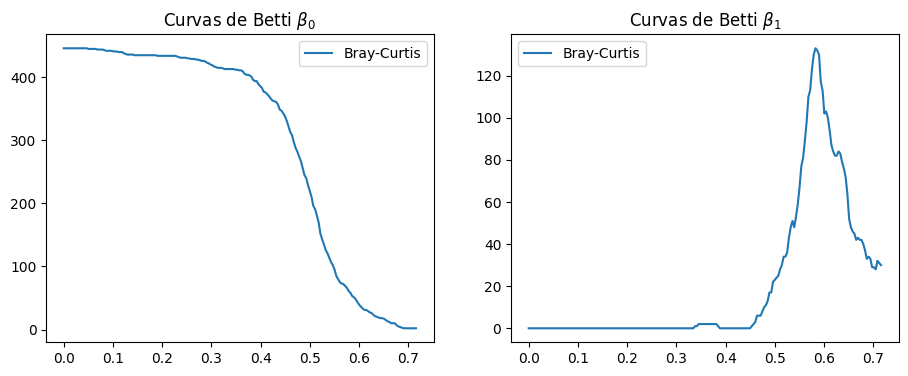


Resumen topológico:


,geometry,max_persistence_beta0,median_persistence_beta0,max_persistence_beta1,median_persistence_beta1,n_beta1_bars,n_beta1_persistence_gt_0.20
0,Bray-Curtis,0.766177,0.497362,0.162526,0.026011,477,0



Top persistencias H1 Bray-Curtis:


,birth,death,persistence
0,0.567729,0.730255,0.162526
1,0.569741,0.724101,0.154361
2,0.643830,0.759249,0.115420
3,0.572284,0.685810,0.113526
4,0.704547,0.817834,0.113287
5,0.689612,0.799770,0.110159
6,0.549719,0.659145,0.109426
7,0.524818,0.633801,0.108983
8,0.528518,0.636100,0.107583
9,0.541194,0.643067,0.101872


/usr/local/lib/python3.12/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


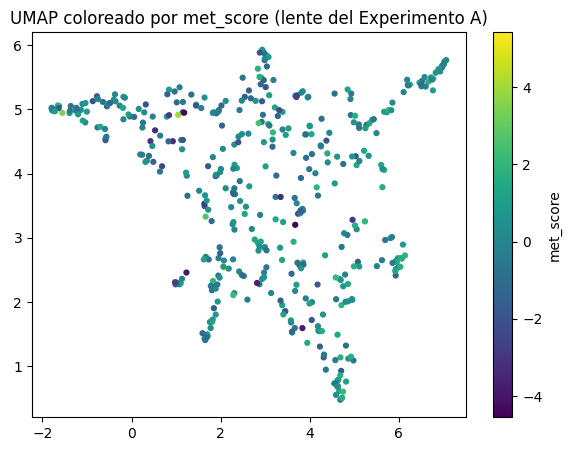


Resumen del grafo Mapper (Exp A):
{'nodes': 55, 'edges': 94, 'components': 6, 'covered_samples_fraction': 0.7354260089686099, 'giant_component_fraction_of_nodes': 0.8181818181818182}


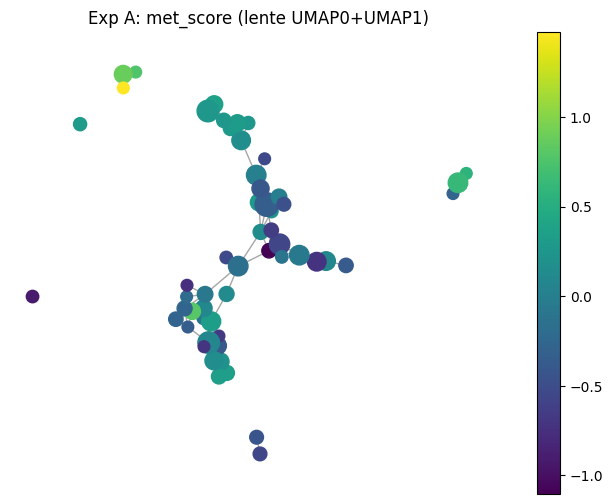

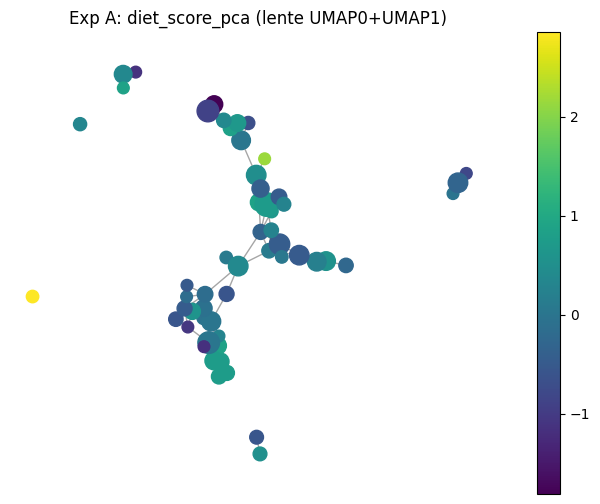


Alignment scores (Exp A — lente UMAP0+UMAP1):


,variable,morans_I,node_range,edge_corr,edge_mad,alignment_score
6,adiponectin,0.287424,2.132954,0.404036,0.281616,0.613063
3,bmi,0.335210,1.730582,0.326297,0.362054,0.580109
11,fiber,0.279777,1.959024,0.406548,0.297978,0.548089
10,hsCRP,0.328404,1.563150,0.224125,0.288357,0.513344
0,met_score,0.213256,2.076682,0.271417,0.326549,0.442864
12,per_total_fat,0.193725,2.169095,0.314055,0.301086,0.420207
4,waist,0.216465,1.879664,0.226186,0.407522,0.406881
2,age,0.296105,1.267415,0.368479,0.294241,0.375288
5,HDL,0.171574,1.956296,0.219777,0.322715,0.335650
13,per_carbohydrates,0.140202,1.893686,0.201570,0.341998,0.265499



Test de permutación (Exp A):


,variable,morans_I,node_range,edge_corr,edge_mad,alignment_score,p_alignment,p_moran,perm_alignment_mean,perm_alignment_sd
0,met_score,0.213256,2.076682,0.271417,0.326549,0.442864,0.392027,0.514950,0.403995,0.223386
1,diet_score_pca,0.097940,2.380428,0.184120,0.305429,0.233139,0.730897,0.843854,0.381263,0.211140
2,age,0.296105,1.267415,0.368479,0.294241,0.375288,0.498339,0.279070,0.400315,0.198920
3,per_total_fat,0.193725,2.169095,0.314055,0.301086,0.420207,0.398671,0.578073,0.386767,0.198155



Extremos continuo cardiometabólico: 69 bajo / 66 alto

Extremos del continuo cardiometabólico (Exp A):


,variable,mean_low,mean_high,diff_high_minus_low,p
0,met_score,-0.575874,0.700329,1.276203,1.064835e-08
8,waist,87.198551,99.719697,12.521146,6.408345e-07
7,bmi,25.830435,30.083333,4.252899,1.135405e-06
14,hsCRP,1.952754,4.371970,2.419216,6.558286e-06
10,adiponectin,8.036522,5.042727,-2.993794,2.334798e-05
9,HDL,50.594203,41.136364,-9.457839,1.033722e-04
12,triglycerides,123.550725,166.030303,42.479578,5.256300e-03
11,glucose,85.710145,91.681818,5.971673,3.598861e-02
13,HOMA_IR,2.964906,3.631659,0.666753,1.250274e-01
6,age,41.304348,39.196970,-2.107378,2.069915e-01


In [ ]:
# EXPERIMENTO A
# Espacio : Bray-Curtis a nivel género (X_bray5, 5 PCoA dims escaladas)
# Lente   : UMAP coord 0 + UMAP coord 1  (2 columnas)
# Métrica : Bray-Curtis

# Curvas de Betti
finite_deaths = []
for dgms in [ph_bray]:
    for dim in [0, 1]:
        d = np.asarray(dgms[dim], dtype=float)
        finite = d[np.isfinite(d[:, 1])]
        if len(finite):
            finite_deaths.extend(finite[:, 1].tolist())

max_scale = np.percentile(finite_deaths, 95)
grid      = np.linspace(0, max_scale, 200)
b0_bray   = betti_curve(ph_bray[0], grid)
b1_bray   = betti_curve(ph_bray[1], grid)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(grid, b0_bray, label="Bray-Curtis"); axes[0].set_title(r"Curvas de Betti $\beta_0$"); axes[0].legend()
axes[1].plot(grid, b1_bray, label="Bray-Curtis"); axes[1].set_title(r"Curvas de Betti $\beta_1$"); axes[1].legend()
plt.show()

summary_ph = pd.DataFrame([persistence_summary(ph_bray, "Bray-Curtis")])
print("\nResumen topológico:"); display(summary_ph)

# Top persistencias H1
h1_arr = np.asarray(ph_bray[1], dtype=float)
h1_fin = h1_arr[np.isfinite(h1_arr[:, 1])]
if len(h1_fin):
    pers   = h1_fin[:, 1] - h1_fin[:, 0]
    order  = np.argsort(-pers)
    top_h1 = pd.DataFrame(h1_fin[order], columns=["birth", "death"])
    top_h1["persistence"] = pers[order]
    print("\nTop persistencias H1 Bray-Curtis:"); display(top_h1.head(10))

# LENTE: UMAP coord 0 + UMAP coord 1
reducer   = umap.UMAP(n_neighbors=15, min_dist=0.01,
                           n_components=2, metric="braycurtis",
                           random_state=42)
X_umap_2d = reducer.fit_transform(X_rel.values)

# Visualización del embedding
fig, ax = plt.subplots(figsize=(7, 5))
sc = ax.scatter(X_umap_2d[:, 0], X_umap_2d[:, 1],
                c=meta_clean["met_score"].values, cmap="viridis", s=12)
plt.colorbar(sc, ax=ax, label="met_score")
ax.set_title("UMAP coloreado por met_score (lente del Experimento A)")
plt.show()

# Lente = las dos coordenadas UMAP normalizadas
lens_A = normalize_cols(X_umap_2d)   # shape (n, 2)

# MAPPER
mapper  = km.KeplerMapper(verbose=0)
graph_A = mapper.map(
    lens=lens_A,
    X=X_bray5,
    cover=km.Cover(n_cubes=10, perc_overlap=0.35),
    clusterer=DBSCAN(eps=1.0, min_samples=4),
)

#Grafo
G_A     = graph_to_nx(graph_A)
covered = set()
for members in graph_A["nodes"].values():
    covered.update(members)

summary_mapper = {
    "nodes":     G_A.number_of_nodes(),
    "edges":     G_A.number_of_edges(),
    "components": nx.number_connected_components(G_A),
    "covered_samples_fraction": len(covered) / len(meta_clean),
    "giant_component_fraction_of_nodes": (
        max(len(c) for c in nx.connected_components(G_A)) / G_A.number_of_nodes()
        if G_A.number_of_nodes() else np.nan),
}
print("\nResumen del grafo Mapper (Exp A):"); print(summary_mapper)

# VISUALIZACIÓN DEL GRAFO
draw_mapper_graph(graph_A, G_A, meta_clean["met_score"],
                  "Exp A: met_score (lente UMAP0+UMAP1)")
draw_mapper_graph(graph_A, G_A, meta_clean["diet_score_pca"],
                  "Exp A: diet_score_pca (lente UMAP0+UMAP1)")

# ALIGNMENT SCORES
continuous_vars = [
    "met_score", "diet_score_pca", "age", "bmi", "waist",
    "HDL", "adiponectin", "glucose", "triglycerides", "HOMA_IR", "hsCRP",
    "fiber", "per_total_fat", "per_carbohydrates", "per_animal_protein",
]
rows_A = []
for var in continuous_vars:
    if var in meta_clean.columns:
        rows_A.append({"variable": var,
                       **mapper_alignment_on_graph(graph_A, G_A, meta_clean[var])})
align_df = pd.DataFrame(rows_A).sort_values("alignment_score", ascending=False)
print("\nAlignment scores (Exp A — lente UMAP0+UMAP1):"); display(align_df)

# TEST DE PERMUTACIÓN
rng_np = np.random.default_rng(42)

perm_vars = ["met_score", "diet_score_pca", "age", "per_total_fat"]
perm_rows = []
for var in perm_vars:
    if var in meta_clean.columns:
        perm_rows.append({"variable": var,
                          **perm_test_on_graph(graph_A, G_A, meta_clean[var])})
perm_df = pd.DataFrame(perm_rows)
print("\nTest de permutación (Exp A):"); display(perm_df)

# EXTREMOS DEL CONTINUO
sample_to_nodes = {i: [] for i in range(len(meta_clean))}
for node, members in graph_A["nodes"].items():
    for m in members:
        sample_to_nodes[m].append(node)

sm_met = sample_smoothed(graph_A, meta_clean["met_score"])
low_met, high_met = compare_extremes(sm_met)
print(f"\nExtremos continuo cardiometabólico: {len(low_met)} bajo / {len(high_met)} alto")

vars_compare = ["met_score", "diet_score_pca", "fiber", "per_total_fat",
                "per_carbohydrates", "per_animal_protein", "age", "bmi",
                "waist", "HDL", "adiponectin", "glucose",
                "triglycerides", "HOMA_IR", "hsCRP"]

ext_table = table_extremes(low_met, high_met)
print("\nExtremos del continuo cardiometabólico (Exp A):"); display(ext_table)

# GÉNEROS DIFERENCIALES ENTRE EXTREMOS
gen_prev   = (X_rel > 0).mean(axis=0)
common_gen = gen_prev[gen_prev >= 0.10].index.tolist()

genus_diff = top_genus_diffs(low_met, high_met)

### **densidad global + local**

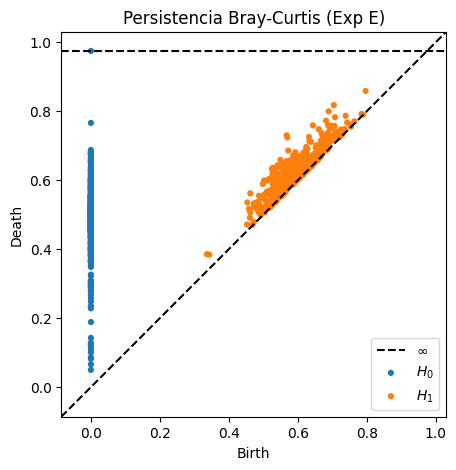

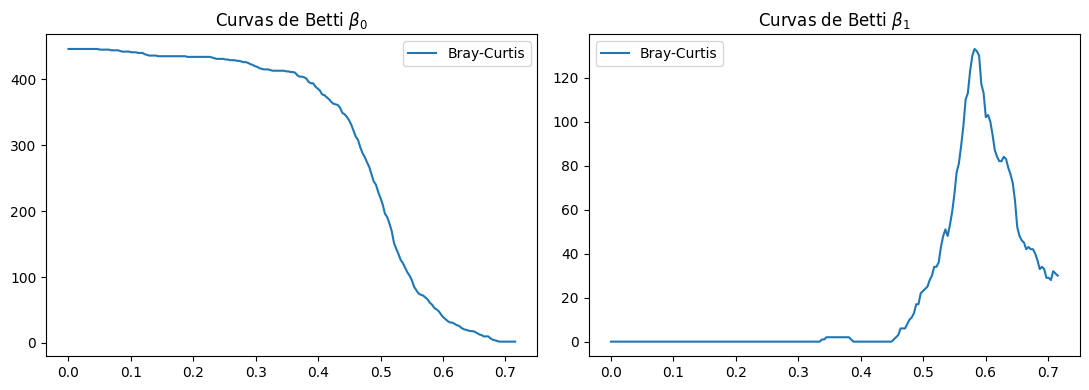


Resumen topológico:


,geometry,max_persistence_beta0,median_persistence_beta0,max_persistence_beta1,median_persistence_beta1,n_beta1_bars,n_beta1_persistence_gt_0.20
0,Bray-Curtis,0.766177,0.497362,0.162526,0.026011,477,0



Top H1:


,birth,death,persistence
0,0.567729,0.730255,0.162526
1,0.569741,0.724101,0.154361
2,0.643830,0.759249,0.115420
3,0.572284,0.685810,0.113526
4,0.704547,0.817834,0.113287
5,0.689612,0.799770,0.110159
6,0.549719,0.659145,0.109426
7,0.524818,0.633801,0.108983
8,0.528518,0.636100,0.107583
9,0.541194,0.643067,0.101872



=== Construyendo lente densidad local + densidad global ===
Densidad local  — media: 1.030 | std: 0.269
Densidad global — media: 3.002 | std: 0.458
Correlación local-global: 0.643


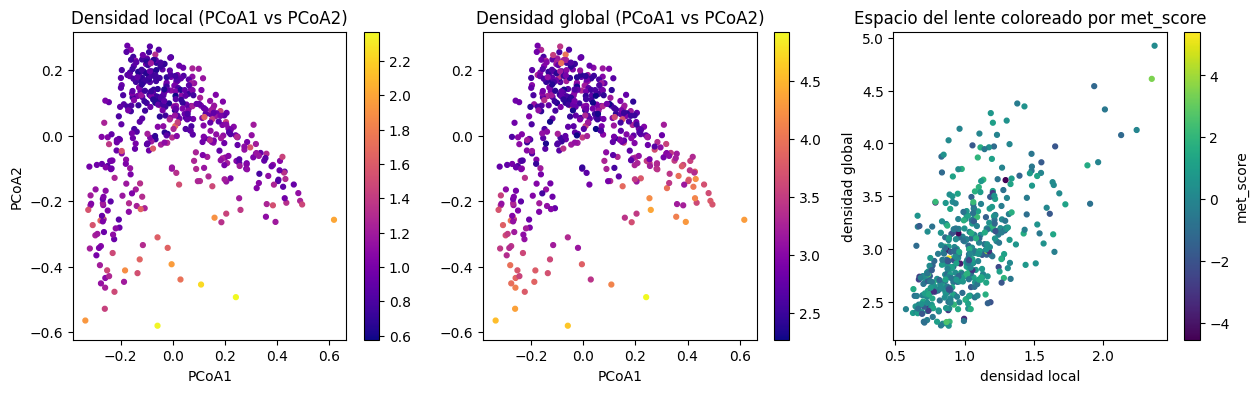


Resumen del grafo Mapper (Exp E):
{'nodes': 43, 'edges': 68, 'components': 10, 'covered_samples_fraction': 0.695067264573991, 'giant_component_fraction_of_nodes': 0.6511627906976745}


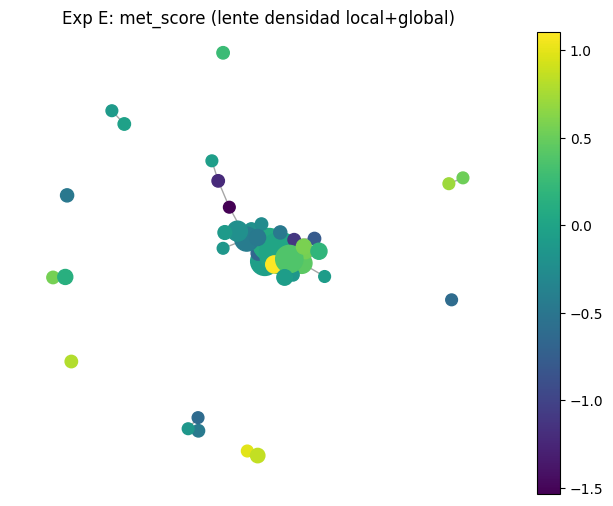

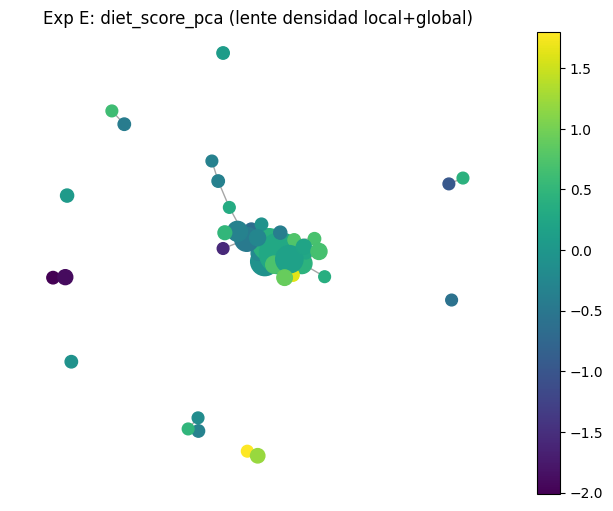


Alignment scores (Exp E — lente densidad local+global):


,variable,morans_I,node_range,edge_corr,edge_mad,alignment_score
0,met_score,0.286940,2.127868,0.404076,0.335348,0.610571
1,diet_score_pca,0.286049,1.943116,0.494504,0.228852,0.555826
6,adiponectin,0.283058,1.845868,0.374695,0.315311,0.522487
11,fiber,0.185022,2.493303,0.397483,0.306472,0.461315
8,triglycerides,0.281559,1.590587,0.455287,0.235916,0.447844
13,per_carbohydrates,0.226633,1.969881,0.414451,0.252549,0.446441
12,per_total_fat,0.256826,1.687178,0.480151,0.227500,0.433312
5,HDL,0.210679,2.029422,0.293586,0.348746,0.427556
9,HOMA_IR,0.087380,4.199077,0.240253,0.326323,0.366914
3,bmi,0.243466,1.295684,0.371418,0.247785,0.315455



Test de permutación (Exp E):


,variable,morans_I,node_range,edge_corr,edge_mad,alignment_score,p_alignment,p_moran,perm_alignment_mean,perm_alignment_sd
0,met_score,0.286940,2.127868,0.404076,0.335348,0.610571,0.129568,0.156146,0.357258,0.216611
1,diet_score_pca,0.286049,1.943116,0.494504,0.228852,0.555826,0.142857,0.159468,0.344060,0.199193
2,age,0.167719,1.617291,0.248288,0.340984,0.271250,0.647841,0.601329,0.361839,0.182940
3,per_total_fat,0.256826,1.687178,0.480151,0.227500,0.433312,0.325581,0.239203,0.367931,0.211056



Extremos cardiometabólicos: 64 bajo / 63 alto

Extremos del continuo cardiometabólico (Exp E):


,variable,mean_low,mean_high,diff_high_minus_low,p
0,met_score,-0.634361,0.788138,1.422499,3.641804e-09
10,adiponectin,8.031094,4.806190,-3.224903,3.305198e-06
9,HDL,53.421875,41.253968,-12.167907,8.557448e-06
12,triglycerides,113.656250,183.079365,69.423115,2.474109e-05
8,waist,89.257812,98.468254,9.210441,3.430498e-04
11,glucose,86.734375,97.984127,11.249752,3.528384e-04
7,bmi,26.851562,29.612698,2.761136,3.810908e-03
2,fiber,16.656250,19.587302,2.931052,1.234510e-02
14,hsCRP,2.372344,3.678254,1.305910,1.809880e-02
13,HOMA_IR,2.862478,3.704381,0.841904,1.257747e-01



Géneros diferenciales (Exp E):


,genus,mean_group1,mean_group2,log2FC_group2_vs_group1,p,q
0,02d06,0.011922,0.003523,-1.758330,0.000001,0.000178
53,Escherichia,0.041833,0.162665,1.959170,0.000020,0.000892
98,Prevotella,0.041036,0.110805,1.433028,0.000024,0.000892
7,Akkermansia,0.084399,0.010483,-3.009091,0.000026,0.000892
43,Dehalobacterium,0.000710,0.000260,-1.446322,0.000061,0.001690
62,Haemophilus,0.002448,0.011628,2.247780,0.000080,0.001849
125,Trigonala,0.000668,0.000179,-1.892966,0.000139,0.002741
51,Enterobacter,0.035493,0.064063,0.851949,0.000161,0.002777
42,Defluviitalea,0.004286,0.000787,-2.444021,0.000382,0.005851
127,Unassigned,0.069539,0.034170,-1.025052,0.000485,0.006698


In [ ]:
# EXPERIMENTO E
# Espacio : Bray-Curtis a nivel género (X_bray5, 5 PCoA dims escaladas)
# Lente   : densidad kNN LOCAL + densidad GLOBAL
#           — ambas calculadas sobre X_bray5, sin ningún modelo intermedio —
# Métrica : Bray-Curtis

# Diagrama de persistencia
fig, ax = plt.subplots(figsize=(6, 5))
plot_diagrams(ph_bray, ax=ax, show=False)
ax.set_title("Persistencia Bray-Curtis (Exp E)")
plt.show()

finite_d = []
for dim in [0,1]:
    d = np.asarray(ph_bray[dim], dtype=float)
    finite = d[np.isfinite(d[:,1])]
    if len(finite): finite_d.extend(finite[:,1].tolist())

max_scale = np.percentile(finite_d, 95)
grid = np.linspace(0, max_scale, 200)

#Curvas de Betti
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(grid, betti_curve(ph_bray[0], grid), label="Bray-Curtis")
axes[0].set_title(r"Curvas de Betti $\beta_0$"); axes[0].legend()
axes[1].plot(grid, betti_curve(ph_bray[1], grid), label="Bray-Curtis")
axes[1].set_title(r"Curvas de Betti $\beta_1$"); axes[1].legend()
plt.tight_layout(); plt.savefig("betti_expE.png", dpi=150); plt.show()

print("\nResumen topológico:")
display(pd.DataFrame([persistence_summary(ph_bray, "Bray-Curtis")]))

# Top H1
h1_arr = np.asarray(ph_bray[1], dtype=float)
h1_fin = h1_arr[np.isfinite(h1_arr[:,1])]
if len(h1_fin):
    pers  = h1_fin[:,1] - h1_fin[:,0]
    order = np.argsort(-pers)
    top   = pd.DataFrame(h1_fin[order], columns=["birth","death"])
    top["persistence"] = pers[order]
    print("\nTop H1:"); display(top.head(10))


# LENTE: DENSIDAD LOCAL + DENSIDAD GLOBAL
print("\n=== Construyendo lente densidad local + densidad global ===")

# Densidad LOCAL — distancia media a los k vecinos más cercanos
# Valor alto = zona dispersa / valor bajo = zona densa
def density_local(X, k=15):
    nbrs  = NearestNeighbors(n_neighbors=k+1).fit(X)
    dists, _ = nbrs.kneighbors(X)
    return dists[:, 1:].mean(axis=1)   # excluye el punto mismo

# Densidad GLOBAL — distancia media a TODOS los demás puntos
# Valor alto = punto periférico / valor bajo = punto central
def density_global(X):
    D = pairwise_distances(X, metric="euclidean")
    np.fill_diagonal(D, np.nan)
    return np.nanmean(D, axis=1)

dens_local  = density_local(X_bray5, k=15)
dens_global = density_global(X_bray5)

print(f"Densidad local  — media: {dens_local.mean():.3f} | std: {dens_local.std():.3f}")
print(f"Densidad global — media: {dens_global.mean():.3f} | std: {dens_global.std():.3f}")
print(f"Correlación local-global: {np.corrcoef(dens_local, dens_global)[0,1]:.3f}")

# Visualización del lente
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

sc0 = axes[0].scatter(coords_bray[:,0], coords_bray[:,1],
                      c=dens_local, cmap="plasma", s=12)
plt.colorbar(sc0, ax=axes[0])
axes[0].set_title("Densidad local (PCoA1 vs PCoA2)")
axes[0].set_xlabel("PCoA1"); axes[0].set_ylabel("PCoA2")

sc1 = axes[1].scatter(coords_bray[:,0], coords_bray[:,1],
                      c=dens_global, cmap="plasma", s=12)
plt.colorbar(sc1, ax=axes[1])
axes[1].set_title("Densidad global (PCoA1 vs PCoA2)")
axes[1].set_xlabel("PCoA1")

sc2 = axes[2].scatter(dens_local, dens_global,
                      c=meta_clean["met_score"].values, cmap="viridis", s=12)
plt.colorbar(sc2, ax=axes[2], label="met_score")
axes[2].set_title("Espacio del lente coloreado por met_score")
axes[2].set_xlabel("densidad local"); axes[2].set_ylabel("densidad global")
plt.show()

# Normalizar lente a [0,1] por columna
lens_E = normalize_cols(np.c_[dens_local, dens_global])

# MAPPER
mapper  = km.KeplerMapper(verbose=0)
graph_E = mapper.map(
    lens=lens_E,
    X=X_bray5,
    cover=km.Cover(n_cubes=10, perc_overlap=0.35),
    clusterer=DBSCAN(eps=1.0, min_samples=4),
)

# Grafo
G_E     = graph_to_nx(graph_E)
covered = set()
for members in graph_E["nodes"].values():
    covered.update(members)

summary_mapper = {
    "nodes":      G_E.number_of_nodes(),
    "edges":      G_E.number_of_edges(),
    "components": nx.number_connected_components(G_E),
    "covered_samples_fraction": len(covered) / len(meta_clean),
    "giant_component_fraction_of_nodes": (
        max(len(c) for c in nx.connected_components(G_E)) / G_E.number_of_nodes()
        if G_E.number_of_nodes() else np.nan),
}
print("\nResumen del grafo Mapper (Exp E):"); print(summary_mapper)

# VISUALIZACIÓN DEL GRAFO
draw_mapper_graph(graph_E, G_E, meta_clean["met_score"],
                  "Exp E: met_score (lente densidad local+global)")
draw_mapper_graph(graph_E, G_E, meta_clean["diet_score_pca"],
                  "Exp E: diet_score_pca (lente densidad local+global)")

# ALIGNMENT SCORES
continuous_vars = [
    "met_score","diet_score_pca","age","bmi","waist",
    "HDL","adiponectin","glucose","triglycerides","HOMA_IR","hsCRP",
    "fiber","per_total_fat","per_carbohydrates","per_animal_protein"
]
rows_E = []
for var in continuous_vars:
    if var in meta_clean.columns:
        rows_E.append({"variable": var,
                       **mapper_alignment_on_graph(graph_E, G_E, meta_clean[var])})
align_df = pd.DataFrame(rows_E).sort_values("alignment_score", ascending=False)
print("\nAlignment scores (Exp E — lente densidad local+global):"); display(align_df)

# TEST DE PERMUTACIÓN
rng_np = np.random.default_rng(42)
perm_vars = ["met_score","diet_score_pca","age","per_total_fat"]
perm_rows = []
for var in perm_vars:
    if var in meta_clean.columns:
        perm_rows.append({"variable": var,
                          **perm_test_on_graph(graph_E, G_E, meta_clean[var])})
perm_df = pd.DataFrame(perm_rows)
print("\nTest de permutación (Exp E):"); display(perm_df)

# EXTREMOS DEL CONTINUO
sample_to_nodes = {i: [] for i in range(len(meta_clean))}
for node, members in graph_E["nodes"].items():
    for m in members:
        sample_to_nodes[m].append(node)

sm_met = sample_smoothed(graph_E, meta_clean["met_score"])
low_met, hi_met = compare_extremes(sm_met)
print(f"\nExtremos cardiometabólicos: {len(low_met)} bajo / {len(hi_met)} alto")

vars_compare = ["met_score","diet_score_pca","fiber","per_total_fat",
                "per_carbohydrates","per_animal_protein","age","bmi",
                "waist","HDL","adiponectin","glucose",
                "triglycerides","HOMA_IR","hsCRP"]



print("\nExtremos del continuo cardiometabólico (Exp E):"); display(table_extremes(low_met, hi_met))

# GÉNEROS DIFERENCIALES
gen_prev   = (X_rel > 0).mean(axis=0)
common_gen = gen_prev[gen_prev >= 0.10].index.tolist()

print("\nGéneros diferenciales (Exp E):"); display(top_genus_diffs(low_met, hi_met).head(20))